In [1]:
import os
import re
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines import AalenJohansenFitter

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# Paths
DATA_DIR = os.path.join('..', 'data')
OUT_DIR  = os.path.join('..', 'output')
SURVIVAL_OUT_DIR = os.path.join(OUT_DIR, 'survival')
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(SURVIVAL_OUT_DIR, exist_ok=True)

NACC_MAIN_PATH = os.path.join(DATA_DIR, 'investigator_nacc72.csv')

# Final cohort export from build_cohort notebook
EXP_NAME = "E8b_vascular_signal"
HORIZON_YEARS = 5
COHORT_PATH = os.path.join(OUT_DIR, f'cohort_{EXP_NAME}_H{HORIZON_YEARS}.csv')

USE_ONLY_V3 = False   # True => keep only FORMVER in {3, 3.2}

# Horizon sweep range
MIN_H = 3
MAX_H = 12

In [2]:
# Survival display labels + display-only hiding for board-ready plots

SURVIVAL_LABELS = {
    "NACCAGE": "Age",
    "SEX": "Sex",
    "RACE": "Race",
    "HISPANIC": "Hispanic",
    "EDUC": "Education",
    "NACCMMSE": "MMSE",
    "NACCMOCA": "MoCA",
    "CDRSUM": "CDR Sum Boxes",
    "CDRGLOB": "CDR Global",
    "CDR_ADL_COG_RATIO": "CDR ADL/Cog Ratio",
    "CDR_ADL_MINUS_COG": "CDR ADL-Cog",
    "NACCGDS": "GDS",
    "DEP2YRS": "Recent Depression",
    "COGFLUC": "Cog Fluctuations",
    "BEVHALL": "Hallucinations",
    "BEREM": "REM Behavior",
    "PARKSIGN": "Parkinsonian Signs",
    "BRADY": "Bradykinesia",
    "RESTTRL": "Left Rest Tremor",
    "RESTTRR": "Right Rest Tremor",
    "RIGIDL": "Left Rigidity",
    "RIGIDR": "Right Rigidity",
    "SLOWINGL": "Left Slowing",
    "SLOWINGR": "Right Slowing",
    "PARKGAIT": "Parkinsonian Gait",
    "GAITDIS": "Gait Disorder",
    "DIABETES": "Diabetes",
    "DIABET": "Diabetes Type",
    "HYPERTEN": "Hypertension",
    "HYPERCHO": "Hypercholesterolemia",
    "CVAFIB": "Atrial Fibrillation",
    "CBSTROKE": "Stroke",
    "CBTIA": "TIA",
    "STROKE_TIA_ANY": "Stroke/TIA History",
    "CVCHF": "Heart Failure",
    "CVANGINA": "Angina",
    "CVBYPASS": "Bypass",
    "CVANGIO": "Angioplasty",
    "CVHVALVE": "Valve Disease",
    "CVOTHR": "Other CV Disease",
    "APNEA": "Sleep Apnea",
    "POSTINST": "Postural Instability",
    "DIGBACCT": "Digit Backward Total",
    "DIGBACLS": "Digit Backward Span",
    "VASC": "Vascular Syndrome",
    "CVD": "Vascular Brain Injury",
    "CVDCOG": "Vascular Cog Impact",
    "CVDIMAG": "Vascular Imaging",
    "IMAGMWMH": "Moderate WMH",
    "IMAGEWMH": "Any WMH",
    "FOCLSYM": "Focal Symptoms",
    "FOCLSIGN": "Focal Signs",
    "HACHIN": "Hachinski",
    "HACHIN_GE_4": "Hachinski ≥4",
    "HACHIN_GE_7": "Hachinski ≥7",
    "VASC_MED_COUNT": "Vascular Medication Count",
    "GAIT_ANY": "Any Gait Disorder",
    "STROKDEC": "Stroke with Decline",
    "STROKMUL": "Multiple Strokes",
    "STROKE_x_EXEC": "Stroke × Exec",
    "NACCMOM": "Maternal Dementia Hx",
    "NACCDAD": "Paternal Dementia Hx",
    "ANIMALS": "Animal Fluency",
    "TRAILA": "Trail A",
    "TRAILB": "Trail B",
    "BOSTON": "Boston Naming",
    "SIVDFIND": "Small Vessel Disease"
}

HIDE_FOR_SURVIVAL_CLINICAL_PLOTS = {
    "CDRSUM",
    "CDRGLOB",
    "NACCMMSE",
    "NACCMOCA",
    "CDR_ADL_COG_RATIO",
    "CDR_ADL_MINUS_COG",
}

def surv_label(name: str) -> str:
    return SURVIVAL_LABELS.get(str(name), str(name))

def keep_survival_display_feature(name: str) -> bool:
    return str(name) not in HIDE_FOR_SURVIVAL_CLINICAL_PLOTS

In [3]:
import matplotlib.pyplot as plt

df = pd.read_csv(NACC_MAIN_PATH, low_memory=False)
df['NACCID'] = df['NACCID'].astype(str)

def save_survival_fig(filename, dpi=200):
    out = os.path.join(SURVIVAL_OUT_DIR, filename)
    plt.tight_layout()
    plt.savefig(out, dpi=dpi, bbox_inches="tight")
    print("Saved:", out)

def make_visit_date(df_: pd.DataFrame) -> pd.Series:
    y = pd.to_numeric(df_['VISITYR'], errors='coerce')
    m = pd.to_numeric(df_['VISITMO'], errors='coerce').fillna(6).astype(int).clip(1, 12)
    d = pd.to_numeric(df_['VISITDAY'], errors='coerce').fillna(15).astype(int).clip(1, 28)
    return pd.to_datetime(dict(year=y, month=m, day=d), errors='coerce')

df['visit_date'] = make_visit_date(df)
df = df.dropna(subset=['NACCID', 'visit_date']).copy()
df = df.sort_values(['NACCID', 'visit_date']).reset_index(drop=True)

if 'FORMVER' in df.columns:
    df['FORMVER'] = pd.to_numeric(df['FORMVER'], errors='coerce')

print('Rows:', len(df), 'Participants:', df['NACCID'].nunique())
df[['NACCID','visit_date'] + ([ 'FORMVER' ] if 'FORMVER' in df.columns else [])].head()

Rows: 207454 Participants: 55268


,NACCID,visit_date,FORMVER
0,NACC000011,2006-04-17,1.0
1,NACC000011,2007-06-18,1.0
2,NACC000011,2008-06-03,2.0
3,NACC000011,2009-08-03,2.0
4,NACC000034,2015-07-16,3.0


In [4]:
# NACC special-code cleanup + harmonization

df = df.copy()

# Replacing structural missing code -4 with NaN everywhere numeric
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].replace(-4, np.nan)

# Replacing common generic unknown codes
COMMON_UNKNOWN_CODES = {8, 9, 88, 99, 888, 999, 8888, 9999}

vars_to_soft_clean = [
    "DIABETES", "DIABET",
    "CVAFIB", "AFIBRILL",
    "APNEA", "SLEEPAP",
    "HYPERTEN", "HYPERT",
    "HYPERCHO", "HYPCHOL",
    "CBSTROKE", "CBTIA",
    "CVDSIGNS", "POSTINST",
    "NACCMMSE", "CDRSUM", "NACCAGE", "EDUC"
]

for col in vars_to_soft_clean:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace(list(COMMON_UNKNOWN_CODES), np.nan)

# 3) Harmonize cross-version medical variables
def combine_binary_cols(df_in, cols, new_name):
    present = [c for c in cols if c in df_in.columns]
    if len(present) == 0:
        return df_in
    x = df_in[present].copy()
    # treating positive values as present, zeros as absent, NaN ignored
    x = x.apply(pd.to_numeric, errors="coerce")
    df_in[new_name] = np.where((x == 1).any(axis=1), 1,
                         np.where((x == 0).any(axis=1), 0, np.nan))
    return df_in

df = combine_binary_cols(df, ["DIABETES", "DIABET"], "diabetes_any")
df = combine_binary_cols(df, ["CVAFIB", "AFIBRILL"], "afib_any")
df = combine_binary_cols(df, ["APNEA", "SLEEPAP"], "sleep_apnea_any")
df = combine_binary_cols(df, ["HYPERTEN", "HYPERT"], "htn_any")
df = combine_binary_cols(df, ["HYPERCHO", "HYPCHOL"], "hyperchol_any")

print("Harmonized columns created:")
for c in ["diabetes_any", "afib_any", "sleep_apnea_any", "htn_any", "hyperchol_any"]:
    if c in df.columns:
        print(c, df[c].value_counts(dropna=False).to_dict())

Harmonized columns created:
diabetes_any {0.0: 178333, 1.0: 16658, nan: 12463}
afib_any {0.0: 188667, 1.0: 15001, nan: 3786}
sleep_apnea_any {nan: 106691, 0.0: 80049, 1.0: 20714}
htn_any {1.0: 104806, 0.0: 96524, nan: 6124}
hyperchol_any {1.0: 109121, 0.0: 89653, nan: 8680}


C:\Users\branjan\AppData\Local\Temp\ipykernel_33988\3353155694.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_in[new_name] = np.where((x == 1).any(axis=1), 1,
C:\Users\branjan\AppData\Local\Temp\ipykernel_33988\3353155694.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_in[new_name] = np.where((x == 1).any(axis=1), 1,
C:\Users\branjan\AppData\Local\Temp\ipykernel_33988\3353155694.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has 

In [5]:


if "DEMENTED" in df.columns:
    no_dem_mask = df["DEMENTED"] == 0
else:
    no_dem_mask = pd.Series(True, index=df.index)

if "NACCUDSD" in df.columns:
    cnmci_mask = df["NACCUDSD"].isin([1,2,3])
else:
    cn_mask = (df["NORMCOG"] == 1) if "NORMCOG" in df.columns else pd.Series(False, index=df.index)
    mci_mask = df["NACCTMCI"].isin([1,2,3,4]) if "NACCTMCI" in df.columns else pd.Series(False, index=df.index)

    if ("NORMCOG" in df.columns) or ("NACCTMCI" in df.columns):
        cnmci_mask = cn_mask | mci_mask
    else:
        cnmci_mask = pd.Series(True, index=df.index)

eligible = df[no_dem_mask & cnmci_mask].copy()

baseline = (
    eligible
    .sort_values(["NACCID","visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

baseline = baseline[["NACCID","visit_date"]]
baseline = baseline.rename(columns={"visit_date":"baseline_date"})

print("Baseline participants:", len(baseline))
baseline.head()

C:\Users\branjan\AppData\Local\Temp\ipykernel_33988\2428668717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline participants: 38341


,NACCID,baseline_date
0,NACC000011,2006-04-17
1,NACC000034,2015-07-16
2,NACC000067,2012-05-23
3,NACC000073,2016-05-20
4,NACC000138,2023-07-13


In [6]:
def years_between(a: pd.Series, b: pd.Series) -> pd.Series:
    return (b - a).dt.days / 365.25

keep_ids = set(baseline['NACCID'])
df2 = df[df['NACCID'].isin(keep_ids)].merge(
    baseline[['NACCID','baseline_date']], on='NACCID', how='left'
).copy()

df2['t_years'] = years_between(df2['baseline_date'], df2['visit_date'])
post = df2[df2['t_years'] > 0].copy()

print("=== CHECKPOINT: post ===")
print("baseline N:", baseline["NACCID"].nunique())
print("post rows:", len(post), " post unique IDs:", post["NACCID"].nunique())
print("post visit_date min/max:", post["visit_date"].min(), post["visit_date"].max())
print("t_years min/max:", post["t_years"].min(), post["t_years"].max())

max_follow = post.groupby('NACCID')['t_years'].max().rename('max_follow_years')
baseline2 = baseline.merge(max_follow, on='NACCID', how='left')

print("\n=== CHECKPOINT: follow-up ===")
print("max_follow_years describe:")
display(baseline2["max_follow_years"].describe())
print("eligible @4y:", (baseline2["max_follow_years"] >= 4).sum())
print("eligible @5y:", (baseline2["max_follow_years"] >= 5).sum())

baseline2['max_follow_years'] = baseline2['max_follow_years'].fillna(0)

#DEMENTED: 0-No, 1-Yes
#NACCUDSD:1-Normal, 2-Impaired not MCI, 3-MCI, 4-Dementia
# if 'NACCUDSD' in post.columns:
#     dem_events_all = post[post['NACCUDSD'] == 4].copy()
#     dementia_def = 'NACCUDSD==4'
# else:
#     dem_events_all = post[post['DEMENTED'] == 1].copy()
#     dementia_def = 'DEMENTED==1'

def get_dementia_events(df_in):
    if "DEMENTED" in df_in.columns:
        return df_in[df_in["DEMENTED"] == 1].copy(), "DEMENTED==1"
    elif "NACCUDSD" in df_in.columns:
        return df_in[df_in["NACCUDSD"] == 4].copy(), "NACCUDSD==4"
    else:
        raise KeyError("Neither DEMENTED nor NACCUDSD found.")
    

dem_events_all, dementia_def = get_dementia_events(post)
first_dem_ever = (dem_events_all.sort_values(['NACCID','visit_date'])
                           .groupby('NACCID', as_index=False)
                           .first()
                           .rename(columns={'visit_date':'dementia_date'}))

first_dem_ever = first_dem_ever.merge(
    baseline2[['NACCID', 'baseline_date', 'max_follow_years']],
    on='NACCID',
    how='left',
    suffixes=('', '_base')   # prevent baseline_date_x/y
)

# Normalizing baseline_date if it got duplicated:
if 'baseline_date' not in first_dem_ever.columns:
    for c in ['baseline_date_base', 'baseline_date_x', 'baseline_date_y']:
        if c in first_dem_ever.columns:
            first_dem_ever['baseline_date'] = first_dem_ever[c]
            break
        
first_dem_ever['time_to_dem_years'] = years_between(first_dem_ever['baseline_date'], first_dem_ever['dementia_date'])

print("\n=== CHECKPOINT: first_dem_ever ===")
print("first_dem_ever unique IDs:", first_dem_ever["NACCID"].nunique())
print("time_to_dem_years min/median/max:",
      first_dem_ever["time_to_dem_years"].min(),
      first_dem_ever["time_to_dem_years"].median(),
      first_dem_ever["time_to_dem_years"].max())

print('Dementia event definition:', dementia_def)
print('Participants with ANY post-baseline dementia event:', first_dem_ever['NACCID'].nunique())
first_dem_ever[['NACCID','baseline_date','dementia_date','time_to_dem_years']].head()

=== CHECKPOINT: post ===
baseline N: 38341
post rows: 123654  post unique IDs: 27703
post visit_date min/max: 2006-04-03 00:00:00 2025-10-21 00:00:00
t_years min/max: 0.008213552361396304 19.392197125256672

=== CHECKPOINT: follow-up ===
max_follow_years describe:


count    27703.000000
mean         5.499126
std          4.268776
min          0.109514
25%          2.080767
50%          4.301164
75%          7.685147
max         19.392197
Name: max_follow_years, dtype: float64

eligible @4y: 14853
eligible @5y: 12474


C:\Users\branjan\AppData\Local\Temp\ipykernel_33988\2108224931.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()



=== CHECKPOINT: first_dem_ever ===
first_dem_ever unique IDs: 5502
time_to_dem_years min/median/max: 0.4188911704312115 2.6885694729637235 19.304585900068446
Dementia event definition: DEMENTED==1
Participants with ANY post-baseline dementia event: 5502


,NACCID,baseline_date,dementia_date,time_to_dem_years
0,NACC000034,2015-07-16,2021-05-21,5.848049
1,NACC000162,2009-03-10,2017-11-10,8.670773
2,NACC000225,2009-09-23,2017-07-07,7.786448
3,NACC000271,2007-06-20,2009-05-14,1.900068
4,NACC000333,2021-05-13,2024-07-24,3.197810


In [7]:
def subtype_primary(row):

    formver = row.get("FORMVER", np.nan)

    # PD / LBD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 2:
        return "PD_LBD"

    # Vascular
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 8:
        return "Vascular"

    # AD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 1:
        return "AD"

    return "Other/Unk"


# Stage 1: Primary
first_dem_ever["subtype_primary_contrib_any"] = first_dem_ever.apply(subtype_primary, axis=1)


print("\nFinal (Primary -> Contrib -> Any) subtype counts:")
display(first_dem_ever["subtype_primary_contrib_any"].value_counts())


Final (Primary -> Contrib -> Any) subtype counts:


subtype_primary_contrib_any
AD           4218
Other/Unk     651
PD_LBD        374
Vascular      259
Name: count, dtype: int64

In [8]:

# Building survival dataset

surv = baseline2[["NACCID", "baseline_date", "max_follow_years"]].copy()

surv = surv.merge(
    first_dem_ever[[
        "NACCID",
        "dementia_date",
        "time_to_dem_years",
        "subtype_primary_contrib_any"
    ]],
    on="NACCID",
    how="left"
)

# Event indicator
surv["event_observed"] = surv["dementia_date"].notna().astype(int)

# Time-to-event
surv["time_to_event"] = np.where(
    surv["event_observed"] == 1,
    surv["time_to_dem_years"],
    surv["max_follow_years"]
)

# Event subtype
surv["event_type"] = np.where(
    surv["event_observed"] == 1,
    surv["subtype_primary_contrib_any"],
    "Censored"
)

print("Survival dataset size:", len(surv))
print(surv["event_type"].value_counts(dropna=False))
surv.head()

Survival dataset size: 38341
event_type
Censored     32839
AD            4218
Other/Unk      651
PD_LBD         374
Vascular       259
Name: count, dtype: int64


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored
3,NACC000073,2016-05-20,0.000000,NaT,NaN,NaN,0,0.000000,Censored
4,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored


In [9]:
# Removing zero follow-up rows
surv = surv[surv["time_to_event"] > 0].copy()


surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()

# Any-dementia event
surv_main["event_any_dementia"] = (surv_main["event_type"] != "Censored").astype(int)

print("After cleanup:", len(surv_main))
print(surv_main["event_type"].value_counts(dropna=False))
print(surv_main["event_any_dementia"].value_counts(dropna=False))

After cleanup: 27052
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_any_dementia
0    22201
1     4851
Name: count, dtype: int64


Saved: ..\output\survival\kaplan–Meier_Curve_Time_to_Any_Dementia.png


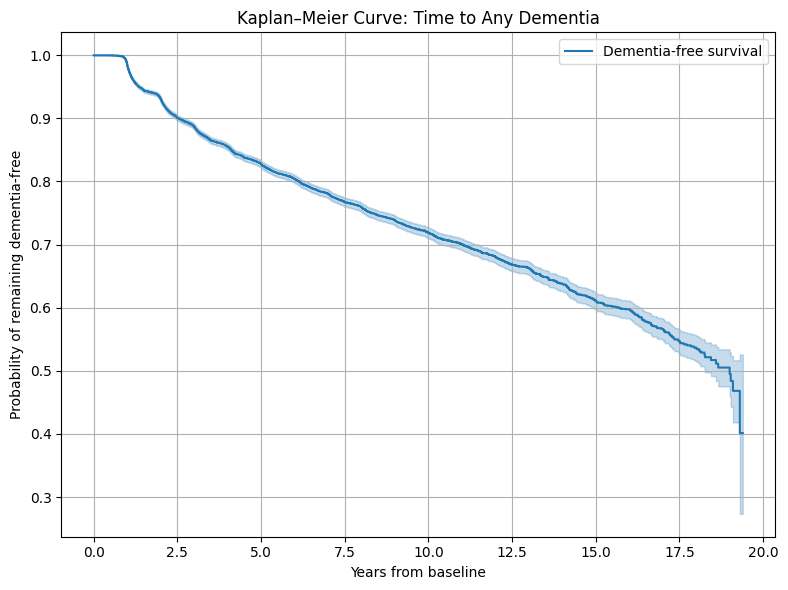

In [10]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations=surv_main["time_to_event"],
    event_observed=surv_main["event_any_dementia"],
    label="Dementia-free survival"
)

plt.figure(figsize=(8,6))
kmf.plot_survival_function()
plt.title("Kaplan–Meier Curve: Time to Any Dementia")
plt.xlabel("Years from baseline")
plt.ylabel("Probability of remaining dementia-free")
plt.grid(True)
save_survival_fig("kaplan–Meier_Curve_Time_to_Any_Dementia.png")
plt.show()

In [11]:
# Load final exported cohort features from build_cohort notebook

cohort_final = pd.read_csv(COHORT_PATH, low_memory=False)
cohort_final["NACCID"] = cohort_final["NACCID"].astype(str)

print("Loaded final cohort file:", COHORT_PATH)
print("cohort_final shape:", cohort_final.shape)
display(cohort_final.head(3))

Loaded final cohort file: ..\output\cohort_E8b_vascular_signal_H5.csv
cohort_final shape: (38341, 85)


,NACCID,baseline_date,label,max_follow_years,has_H_followup,has_dementia_H,NACCAGE,SEX,RACE,HISPANIC,EDUC,NACCUDSD,NACCMMSE,NACCMOCA,TRAILA,TRAILB,ANIMALS,BOSTON,CDRSUM,CDRGLOB,NACCMMSE_missing,NACCMOCA_missing,TRAILA_missing,TRAILB_missing,CDRSUM_missing,COGFLUC,BEVHALL,BEREM,PARKSIGN,BRADY,RESTTRL,RESTTRR,RIGIDL,RIGIDR,SLOWINGL,SLOWINGR,PARKGAIT,GAITDIS,DIABETES,HYPERTEN,HYPERCHO,CVAFIB,CBSTROKE,CBTIA,CVCHF,CVANGINA,CVBYPASS,CVANGIO,CVHVALVE,CVOTHR,APNEA,DEP2YRS,DIABET,POSTINST,NACCGDS,DIGBACCT,DIGBACLS,CVD,VASC,CVDCOG,CVDIMAG,IMAGMWMH,IMAGEWMH,FOCLSYM,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,STROKE_TIA_ANY,VASC_MED_COUNT,GAIT_ANY,CDR_ADL_COG_RATIO,CDR_ADL_MINUS_COG,STROKE_x_EXEC,STROKDEC,STROKMUL,COMMUN,HOMEHOBB,PERSCARE,MEMORY,ORIENT,JUDGMENT,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,Censored,3.296372,False,False,62.0,2.0,1.0,0.0,16.0,3.0,30.0,NaN,32.0,76.0,20.0,27.0,0.5,0.5,0,1,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,-0.5,-0.0,NaN,NaN,0.0,0.0,0.0,0.5,0.0,0.0,NaN,NaN,NaN
1,NACC000034,2015-07-16,NoDementia_Hy,6.986995,True,False,79.0,2.0,1.0,0.0,15.0,3.0,NaN,27.0,52.0,155.0,15.0,NaN,0.5,0.5,1,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2.0,0,0.0,-0.5,-0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.0,1.0,1.0,0.0
2,NACC000067,2012-05-23,Censored,2.088980,False,False,60.0,1.0,1.0,0.0,18.0,3.0,29.0,NaN,47.0,105.0,21.0,29.0,0.5,0.0,0,1,0,0,0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,1.0,NaN,NaN,13.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,1.0,1,0.0,-0.5,-0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.5,1.0,0.0,NaN


In [12]:
# Exact final E8b feature list from build_cohort

E8B_FEATURES = [
    # Demographic
    "NACCAGE","SEX","RACE","HISPANIC","EDUC",

    # Cognitive / function
    "NACCMMSE","NACCMOCA","TRAILA","TRAILB","ANIMALS","BOSTON",
    "CDRSUM","CDRGLOB",
    "NACCMMSE_missing","NACCMOCA_missing","TRAILA_missing","TRAILB_missing","CDRSUM_missing",

    # Motor / PD-LBD
    "COGFLUC","BEVHALL","BEREM",
    "PARKSIGN","BRADY","RESTTRL","RESTTRR","RIGIDL","RIGIDR",
    "SLOWINGL","SLOWINGR","PARKGAIT","GAITDIS",

    # Medical / vascular / selected extras used in E8b
    "DIABETES","HYPERTEN","HYPERCHO","CVAFIB","CBSTROKE","CBTIA",
    "CVCHF","CVANGINA","CVBYPASS","CVANGIO","CVHVALVE","CVOTHR",
    "APNEA","DEP2YRS",
    "DIABET","POSTINST","NACCGDS","DIGBACCT","DIGBACLS",
    "CVD","VASC","CVDCOG","CVDIMAG","IMAGMWMH","IMAGEWMH",
    "FOCLSYM","FOCLSIGN","HACHIN",
    "HACHIN_GE_4","HACHIN_GE_7",
    "STROKE_TIA_ANY","VASC_MED_COUNT","GAIT_ANY",
    "CDR_ADL_COG_RATIO","CDR_ADL_MINUS_COG",
    "STROKE_x_EXEC","STROKDEC","STROKMUL",

    # Family / imaging extra
    "NACCMOM","NACCDAD","SIVDFIND"
]

base_cols_needed = ["NACCID", "label", "max_follow_years", "has_H_followup", "has_dementia_H"]

present_e8b = [c for c in E8B_FEATURES if c in cohort_final.columns]
missing_e8b = [c for c in E8B_FEATURES if c not in cohort_final.columns]

print("Present E8b features:", len(present_e8b))
print("Missing E8b features:", len(missing_e8b))
print("Missing:", missing_e8b)

cohort_features = cohort_final[["NACCID"] + present_e8b].copy()
print("cohort_features shape:", cohort_features.shape)

Present E8b features: 72
Missing E8b features: 0
Missing: []
cohort_features shape: (38341, 73)


In [13]:
# Merge final E8b feature export onto survival outcome dataframe

cox_df = surv_main.merge(cohort_features, on="NACCID", how="left")

# Recompute binary event just to be safe
cox_df["event_any_dementia"] = (cox_df["event_type"] != "Censored").astype(int)

print("Rows after merge:", len(cox_df))
print("Merged columns:", len(cox_df.columns))
display(cox_df.head(3))

Rows after merge: 27052
Merged columns: 82


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type,event_any_dementia,NACCAGE,SEX,RACE,HISPANIC,EDUC,NACCMMSE,NACCMOCA,TRAILA,TRAILB,ANIMALS,BOSTON,CDRSUM,CDRGLOB,NACCMMSE_missing,NACCMOCA_missing,TRAILA_missing,TRAILB_missing,CDRSUM_missing,COGFLUC,BEVHALL,BEREM,PARKSIGN,BRADY,RESTTRL,RESTTRR,RIGIDL,RIGIDR,SLOWINGL,SLOWINGR,PARKGAIT,GAITDIS,DIABETES,HYPERTEN,HYPERCHO,CVAFIB,CBSTROKE,CBTIA,CVCHF,CVANGINA,CVBYPASS,CVANGIO,CVHVALVE,CVOTHR,APNEA,DEP2YRS,DIABET,POSTINST,NACCGDS,DIGBACCT,DIGBACLS,CVD,VASC,CVDCOG,CVDIMAG,IMAGMWMH,IMAGEWMH,FOCLSYM,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,STROKE_TIA_ANY,VASC_MED_COUNT,GAIT_ANY,CDR_ADL_COG_RATIO,CDR_ADL_MINUS_COG,STROKE_x_EXEC,STROKDEC,STROKMUL,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored,0,62.0,2.0,1.0,0.0,16.0,30.0,NaN,32.0,76.0,20.0,27.0,0.5,0.5,0,1,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,-0.5,-0.0,NaN,NaN,NaN,NaN,NaN
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD,1,79.0,2.0,1.0,0.0,15.0,NaN,27.0,52.0,155.0,15.0,NaN,0.5,0.5,1,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2.0,0,0.0,-0.5,-0.0,0.0,0.0,1.0,1.0,0.0
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored,0,60.0,1.0,1.0,0.0,18.0,29.0,NaN,47.0,105.0,21.0,29.0,0.5,0.0,0,1,0,0,0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,1.0,NaN,NaN,13.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,1.0,1,0.0,-0.5,-0.0,NaN,NaN,1.0,0.0,NaN


In [14]:
# Survival-aligned modeling subsets
# These are ALL drawn only from the final E8b feature export.

SURVIVAL_CORE_FEATURES = [
    "NACCAGE","SEX","EDUC",
    #"NACCMMSE","CDRSUM","CDRGLOB",
    "DEP2YRS","NACCGDS",

    "DIABETES","DIABET","HYPERTEN","HYPERCHO","CVAFIB",
    "CBSTROKE","CBTIA","STROKE_TIA_ANY",
    "CVD","VASC","CVDCOG","CVDIMAG",
    "IMAGMWMH","IMAGEWMH",
    "FOCLSYM","FOCLSIGN","HACHIN","HACHIN_GE_4","HACHIN_GE_7",
    "POSTINST","VASC_MED_COUNT","GAIT_ANY",
    "STROKDEC","STROKMUL","STROKE_x_EXEC",

    "TRAILA","TRAILB","DIGBACCT","DIGBACLS",
    "CDR_ADL_COG_RATIO","CDR_ADL_MINUS_COG",

    "COGFLUC","BEVHALL","BEREM","PARKSIGN","BRADY","PARKGAIT","GAITDIS",

    "NACCMOM","NACCDAD","SIVDFIND"
]

ANY_DEMENTIA_FEATURES = [c for c in SURVIVAL_CORE_FEATURES if c in cox_df.columns]

CAUSE_SPECIFIC_FEATURES = [c for c in SURVIVAL_CORE_FEATURES if c in cox_df.columns]

print("ANY_DEMENTIA_FEATURES:", ANY_DEMENTIA_FEATURES)

ANY_DEMENTIA_FEATURES: ['NACCAGE', 'SEX', 'EDUC', 'DEP2YRS', 'NACCGDS', 'DIABETES', 'DIABET', 'HYPERTEN', 'HYPERCHO', 'CVAFIB', 'CBSTROKE', 'CBTIA', 'STROKE_TIA_ANY', 'CVD', 'VASC', 'CVDCOG', 'CVDIMAG', 'IMAGMWMH', 'IMAGEWMH', 'FOCLSYM', 'FOCLSIGN', 'HACHIN', 'HACHIN_GE_4', 'HACHIN_GE_7', 'POSTINST', 'VASC_MED_COUNT', 'GAIT_ANY', 'STROKDEC', 'STROKMUL', 'STROKE_x_EXEC', 'TRAILA', 'TRAILB', 'DIGBACCT', 'DIGBACLS', 'CDR_ADL_COG_RATIO', 'CDR_ADL_MINUS_COG', 'COGFLUC', 'BEVHALL', 'BEREM', 'PARKSIGN', 'BRADY', 'PARKGAIT', 'GAITDIS', 'NACCMOM', 'NACCDAD', 'SIVDFIND']


In [15]:
# Build Cox dataframe from aligned E8b features

model_cols = ["time_to_event", "event_any_dementia"] + ANY_DEMENTIA_FEATURES
cox_df_model = cox_df[model_cols].copy()

print("cox_df_model shape:", cox_df_model.shape)
display(cox_df_model.head(3))

cox_df_model shape: (27052, 48)


,time_to_event,event_any_dementia,NACCAGE,SEX,EDUC,DEP2YRS,NACCGDS,DIABETES,DIABET,HYPERTEN,HYPERCHO,CVAFIB,CBSTROKE,CBTIA,STROKE_TIA_ANY,CVD,VASC,CVDCOG,CVDIMAG,IMAGMWMH,IMAGEWMH,FOCLSYM,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,POSTINST,VASC_MED_COUNT,GAIT_ANY,STROKDEC,STROKMUL,STROKE_x_EXEC,TRAILA,TRAILB,DIGBACCT,DIGBACLS,CDR_ADL_COG_RATIO,CDR_ADL_MINUS_COG,COGFLUC,BEVHALL,BEREM,PARKSIGN,BRADY,PARKGAIT,GAITDIS,NACCMOM,NACCDAD,SIVDFIND
0,3.296372,0,62.0,2.0,16.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0,NaN,NaN,-0.0,32.0,76.0,NaN,NaN,0.0,-0.5,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
1,5.848049,1,79.0,2.0,15.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,2.0,0,0.0,0.0,-0.0,52.0,155.0,5.0,4.0,0.0,-0.5,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,0.0
2,2.088980,0,60.0,1.0,18.0,1.0,13.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1,NaN,NaN,-0.0,47.0,105.0,NaN,NaN,0.0,-0.5,0.0,0.0,1.0,NaN,NaN,NaN,1.0,1.0,0.0,NaN


In [16]:
# Missing-value handling

for col in cox_df_model.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue

    cox_df_model[col] = pd.to_numeric(cox_df_model[col], errors="coerce")

    if cox_df_model[col].notna().sum() == 0:
        cox_df_model[col] = 0
    else:
        cox_df_model[col] = cox_df_model[col].fillna(cox_df_model[col].median())

In [17]:
cox_df_model = cox_df_model[
    cox_df_model["time_to_event"].notna() &
    (cox_df_model["time_to_event"] > 0)
].copy()

print("Final Cox rows:", len(cox_df_model))
print("Final Cox columns:", len(cox_df_model.columns))

Final Cox rows: 27052
Final Cox columns: 48


In [18]:
from lifelines import CoxPHFitter

cox = CoxPHFitter(penalizer=0.1)
cox.fit(
    cox_df_model,
    duration_col="time_to_event",
    event_col="event_any_dementia"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 27052 total observations, 22201 right-censored observations>
             duration col = 'time_to_event'
                event col = 'event_any_dementia'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 27052
number of events observed = 4851
   partial log-likelihood = -43248.93
         time fit was run = 2026-03-15 17:22:34 UTC

---
                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                          
NACCAGE            0.03      1.03      0.00            0.03            0.04                1.03                1.04
SEX               -0.12      0.88      0.02           -0.17           -0.08                0.84                0.93
EDUC               0.00      1.00      0.00           -0.00            0.00                1.00                1.00
DEP2YRS            0.14      1.15      0.03            0.09            0.20                1.09                1.22
NACCGDS            0.04      1.04      0.01            0.03            0.05                1.03                1.05
DIABETES          -0.03      0.97      0.03           -0.10            0.03                0.91                1.03
DIABET            -0.06      0.94      0.03           -0.12           -0.00                0.89                1.00
HYPERTEN           0.01      1.01      0.02           -0.04            0.05                0.96                1.05
HYPERCHO           0.02      1.03      0.02           -0.02            0.07                0.98                1.07
CVAFIB             0.07      1.08      0.03            0.01            0.14                1.01                1.15
CBSTROKE           0.05      1.05      0.04           -0.03            0.12                0.97                1.13
CBTIA              0.04      1.04      0.04           -0.03            0.11                0.97                1.12
STROKE_TIA_ANY     0.07      1.07      0.06           -0.05            0.18                0.95                1.20
CVD                0.02      1.02      0.08           -0.14            0.17                0.87                1.18
VASC               0.17      1.18      0.14           -0.10            0.44                0.90                1.55
CVDCOG            -0.15      0.86      0.10           -0.35            0.04                0.71                1.04
CVDIMAG            0.36      1.44      0.12            0.12            0.61                1.13                1.83
IMAGMWMH           0.04      1.04      0.08           -0.12            0.20                0.88                1.23
IMAGEWMH          -0.05      0.95      0.20           -0.45            0.34                0.64                1.40
FOCLSYM           -0.07      0.93      0.09           -0.25            0.11                0.78                1.12
FOCLSIGN           0.10      1.10      0.07           -0.05            0.24                0.95                1.27
HACHIN            -0.01      0.99      0.02           -0.04            0.03                0.96                1.03
HACHIN_GE_4        0.07      1.08      0.10           -0.11            0.26                0.89                1.30
HACHIN_GE_7       -0.19      0.83      0.15           -0.48            0.10                0.62                1.11
POSTINST           0.18      1.20      0.14           -0.09            0.46                0.91                1.58
VASC_MED_COUNT    -0.00      1.00      0.01           -0.02            0.02                0.98                1.02
GAIT_ANY           0.12      1.13      0.11           -0.08            0.33                0.92                1.39
STROKDEC          -0.27      0.76      0.27           -0.80            0.26                0.45                1.30
STROKMUL          -0.15      0.86      0.30           -0.73         

In [19]:
# PH-compliant model using restricted cubic splines for age
# and stratification by SEX
# Research basis: Goerdten et al. 2020 (Alzheimer's & Dementia: TRCI)
# showed RCS improved C-index by 0.009 over standard Cox for dementia prediction.
# Harrell recommends 4 knots for N > 5000.

import numpy as np
from patsy import dmatrix

cox_df_model_rcs = cox_df_model.copy()

# Generate RCS basis functions for age (4 knots at 5th, 35th, 65th, 95th percentiles)
age_vals = cox_df_model_rcs["NACCAGE"]
knots = np.percentile(age_vals.dropna(), [5, 35, 65, 95])

# patsy creates the spline basis columns
age_spline = dmatrix(
    f"cr(NACCAGE, knots={list(knots[1:-1])})",  # cr = natural/restricted cubic spline
    {"NACCAGE": age_vals},
    return_type="dataframe"
)
# Drop the intercept column patsy adds
age_spline = age_spline.iloc[:, 1:]
age_spline.columns = [f"NACCAGE_rcs{i}" for i in range(len(age_spline.columns))]

# Replace raw NACCAGE with spline terms
cox_df_rcs = cox_df_model_rcs.drop(columns=["NACCAGE"])
cox_df_rcs = pd.concat([cox_df_rcs, age_spline], axis=1)

# Stratify by SEX (removes PH violation without losing power)
# Research basis: Austin 2022 (Statistics in Medicine) recommends
# stratification when SEX is a confounder, not of primary interest.
main_strata = ["SEX"] if "SEX" in cox_df_rcs.columns else None

cox_rcs = CoxPHFitter(penalizer=0.1)
cox_rcs.fit(
    cox_df_rcs,
    duration_col="time_to_event",
    event_col="event_any_dementia",
    strata=main_strata
)

print("=== Cox PH with RCS age + SEX stratification ===")
cox_rcs.print_summary()
print(f"\nConcordance: {cox_rcs.concordance_index_:.4f}")
print(f"(Previous model concordance: {cox.concordance_index_:.4f})")

=== Cox PH with RCS age + SEX stratification ===


model,lifelines.CoxPHFitter
duration col,'time_to_event'
event col,'event_any_dementia'
penalizer,0.1
l1 ratio,0.0
strata,SEX
baseline estimation,breslow
number of observations,27052
number of events observed,4851
partial log-likelihood,-39759.51
time fit was run,2026-03-15 17:22:38 UTC



Concordance: 0.8504
(Previous model concordance: 0.8565)


In [20]:
hr_table = cox.summary[[
    "coef",
    "exp(coef)",
    "se(coef)",
    "p"
]].copy()

hr_table = hr_table.rename(columns={
    "coef": "log_hazard",
    "exp(coef)": "hazard_ratio",
    "se(coef)": "se",
    "p": "p_value"
})

hr_table.sort_values("p_value").head(20)

,log_hazard,hazard_ratio,se,p_value
covariate,,,,
CDR_ADL_COG_RATIO,1.109829,3.033839,0.028131,0.000000e+00
CDR_ADL_MINUS_COG,-1.037774,0.354242,0.020793,0.000000e+00
NACCAGE,0.033748,1.034323,0.001286,8.622013e-152
TRAILB,0.000743,1.000743,0.000060,1.158125e-35
NACCGDS,0.035739,1.036386,0.005056,1.556951e-12
COGFLUC,0.460061,1.584171,0.086948,1.215160e-07
SEX,-0.122667,0.884558,0.023687,2.233646e-07
DEP2YRS,0.143238,1.154004,0.027976,3.054780e-07
BEREM,0.357729,1.430078,0.073642,1.187758e-06


Saved: ..\output\survival\top_CoxPH_Predictors_for_Time_to_any_dementia_clinical.png


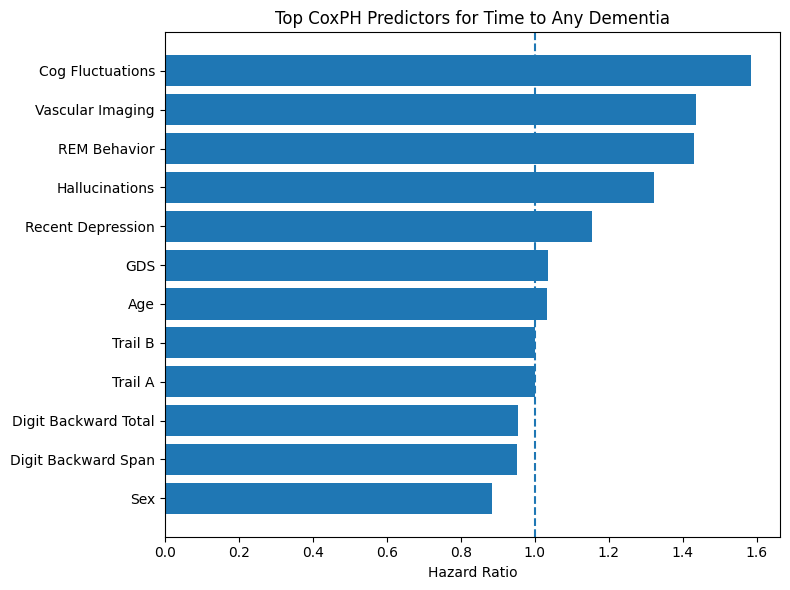

In [21]:
import matplotlib.pyplot as plt

# Build HR table robustly from Cox summary
top_hr_display = cox.summary[["exp(coef)", "p"]].copy()
top_hr_display = top_hr_display.rename(columns={
    "exp(coef)": "hazard_ratio",
    "p": "p_value"
})

# Reset index and rename first column to feature regardless of its original name
top_hr_display = top_hr_display.reset_index()
top_hr_display = top_hr_display.rename(columns={
    top_hr_display.columns[0]: "feature"
})

# Display-only filtering
top_hr_display = top_hr_display.loc[
    top_hr_display["feature"].apply(keep_survival_display_feature)
].copy()

# Keep top significant features, then sort for plotting
top_hr_display = (
    top_hr_display
    .sort_values("p_value")
    .head(12)
    .sort_values("hazard_ratio")
    .copy()
)

# Human-readable labels
top_hr_display["feature_label"] = top_hr_display["feature"].apply(surv_label)

plt.figure(figsize=(8, 6))
plt.barh(top_hr_display["feature_label"], top_hr_display["hazard_ratio"])
plt.axvline(1.0, linestyle="--")
plt.xlabel("Hazard Ratio")
plt.title("Top CoxPH Predictors for Time to Any Dementia")
save_survival_fig("top_CoxPH_Predictors_for_Time_to_any_dementia_clinical.png")
plt.show()

In [22]:
cox.check_assumptions(cox_df_model, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'NACCAGE' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'NACCAGE' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'NACCAGE' using pd.cut, and then specify it in
`strata=['NACCAGE', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'FOCLSYM' failed the non-proportional test: p-value is 0.0272.

   Advice: with so few unique values (only 2), you can include `strata=['FOCLSYM', ...]` in the call
in `.fit`. See documentation in link [E] below.

3. Variable 'FOCLSIGN' failed the non-proportional test: p-value is 0.0428.

   Advice: with so few unique values (only 2), you can 

[]

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter, AalenJohansenFitter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [24]:
# master modeling dataframe

# Starting from cox_df (already merged with baseline features)
model_df = cox_df.copy()

# Binary event
model_df["event_any_dementia"] = (model_df["event_type"] != "Censored").astype(int)

# Keeping only rows with valid time
model_df = model_df[
    model_df["time_to_event"].notna() &
    (model_df["time_to_event"] > 0)
].copy()

print("model_df shape:", model_df.shape)
print(model_df["event_type"].value_counts(dropna=False))

model_df shape: (27052, 82)
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64


1) competing risks
Cell below — Numeric code for competing events

In [25]:
# competing risk event coding:
# 0 = censored
# 1 = AD
# 2 = PD_LBD
# 3 = Vascular

event_code_map = {
    "Censored": 0,
    "AD": 1,
    "PD_LBD": 2,
    "Vascular": 3
}

cr_df = model_df[model_df["event_type"].isin(event_code_map.keys())].copy()
cr_df["event_code"] = cr_df["event_type"].map(event_code_map).astype(int)

print(cr_df["event_type"].value_counts())
print(cr_df["event_code"].value_counts())

event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_code
0    22201
1     4218
2      374
3      259
Name: count, dtype: int64


Cell below — Cumulative incidence curves (Aalen-Johansen)


### Methodological note on competing risks

This notebook uses **cause-specific Cox models** rather than Fine-Gray subdistribution
hazard models. This choice follows Austin, Lee & Fine (2016, *Circulation*): cause-specific
models address the etiological question "what drives vascular dementia risk among event-free
patients?" while Fine-Gray addresses the prognostic question "what is the absolute probability?"

For prognostic use, we derive cumulative incidence functions (CIFs) from the Aalen-Johansen
estimator, which correctly accounts for competing risks without requiring the Fine-Gray
subdistribution assumption. The tied-event jittering warnings are expected for visit-based
NACC data and introduce negligible bias (perturbation ~1e-5 years).

No native Python implementation of Fine-Gray regression exists. If needed, the `cmprsk`
package via rpy2 provides access to the R implementation.

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


Saved: ..\output\survival\cumulative_incidence_by_Dementia_Etiology.png


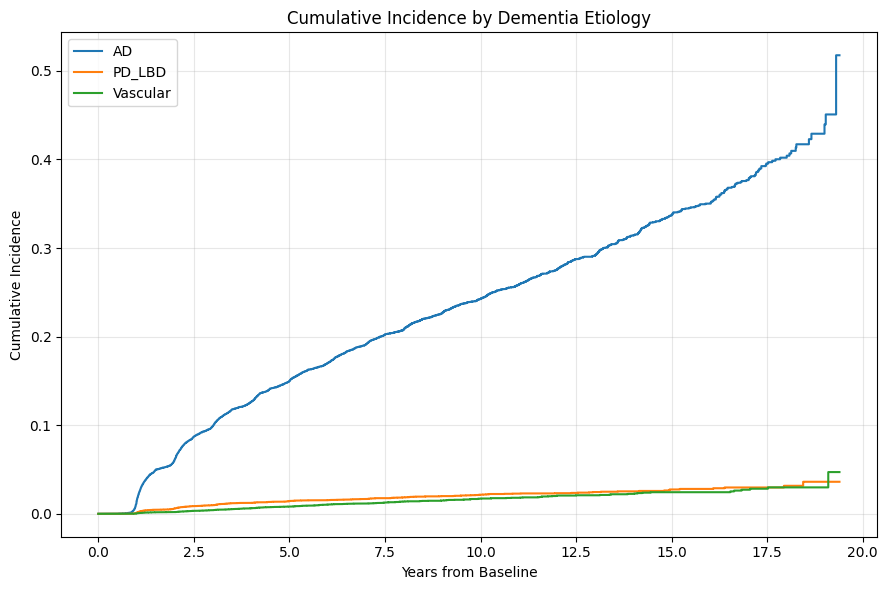

In [26]:
# cumulative incidence curves for competing risks

plt.figure(figsize=(9, 6))

for event_name, event_code in [("AD", 1), ("PD_LBD", 2), ("Vascular", 3)]:
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )
    ajf.plot(ci_show=False)

plt.title("Cumulative Incidence by Dementia Etiology")
plt.xlabel("Years from Baseline")
plt.ylabel("Cumulative Incidence")
plt.grid(True, alpha=0.3)
plt.legend(["AD", "PD_LBD", "Vascular"])
save_survival_fig("cumulative_incidence_by_Dementia_Etiology.png")
plt.show()

# Milestone cumulative incidence table

In [27]:
# Competing-risk cumulative incidence milestone table

milestone_years = [5, 10, 15]
event_map = {"AD": 1, "PD_LBD": 2, "Vascular": 3}

aj_tables = {}

for event_name, event_code in event_map.items():
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )

    cif_vals = []
    for yr in milestone_years:
        # nearest available timepoint
        idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
        cif_val = float(ajf.cumulative_density_.iloc[idx, 0])
        cif_vals.append(cif_val)

    aj_tables[event_name] = cif_vals

cif_milestone_table = pd.DataFrame(aj_tables, index=milestone_years)
cif_milestone_table.index.name = "Years"
display(cif_milestone_table)

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


,AD,PD_LBD,Vascular
Years,,,
5,0.149813,0.014207,0.008154
10,0.242770,0.021563,0.017068
15,0.336779,0.027463,0.024372


2) cause-specific cox model
Cell below — helps to fit cause-specific Cox

In [28]:
# cause-specific cox helper

def fit_cause_specific_cox(df, event_name, features, penalizer=0.1):
    tmp = df.copy()
    tmp["event_cs"] = (tmp["event_type"] == event_name).astype(int)

    use_cols = ["time_to_event", "event_cs"] + [c for c in features if c in tmp.columns]
    tmp = tmp[use_cols].copy()

    for col in tmp.columns:
        if col in ["time_to_event", "event_cs"]:
            continue
        if pd.api.types.is_numeric_dtype(tmp[col]):
            tmp[col] = tmp[col].fillna(tmp[col].median())
        else:
            mode_vals = tmp[col].mode()
            if len(mode_vals) > 0:
                tmp[col] = tmp[col].fillna(mode_vals.iloc[0])

    # one-hot encoding categorical
    cat_cols = [c for c in tmp.columns if c not in ["time_to_event", "event_cs"] and not pd.api.types.is_numeric_dtype(tmp[c])]
    if len(cat_cols) > 0:
        tmp = pd.get_dummies(tmp, columns=cat_cols, drop_first=True)

    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(tmp, duration_col="time_to_event", event_col="event_cs")
    return cph, tmp

Cell below — Running cause-specific Cox for AD / PD_LBD / Vascular

In [29]:
# cause-specific cox models using aligned E8b features

cause_features = [c for c in CAUSE_SPECIFIC_FEATURES if c in model_df.columns]

cause_models = {}
cause_dfs = {}

for outcome in ["AD", "PD_LBD", "Vascular"]:
    cph, tmp_df = fit_cause_specific_cox(model_df, outcome, cause_features, penalizer=0.1)
    cause_models[outcome] = cph
    cause_dfs[outcome] = tmp_df

    print("\n" + "=" * 70)
    print(f"CAUSE-SPECIFIC COX FOR: {outcome}")
    print("=" * 70)
    display(
        cph.summary[["coef", "exp(coef)", "se(coef)", "p"]]
        .sort_values("p")
        .head(15)
    )


CAUSE-SPECIFIC COX FOR: AD


,coef,exp(coef),se(coef),p
covariate,,,,
CDR_ADL_MINUS_COG,-1.049363,0.350161,0.021823,0.000000e+00
CDR_ADL_COG_RATIO,1.103460,3.014578,0.031104,1.136966e-275
NACCAGE,0.032522,1.033057,0.001331,5.872480e-132
TRAILB,0.000647,1.000647,0.000063,7.296165e-25
NACCGDS,0.032596,1.033133,0.005346,1.079204e-09
DEP2YRS,0.131892,1.140985,0.029322,6.860384e-06
DIGBACCT,-0.040247,0.960552,0.010903,2.230331e-04
SEX,-0.088514,0.915291,0.024661,3.316353e-04
BEREM,-0.258197,0.772443,0.096459,7.433632e-03



CAUSE-SPECIFIC COX FOR: PD_LBD


,coef,exp(coef),se(coef),p
covariate,,,,
BEREM,2.579493,13.190444,0.116719,3.160254e-108
BEVHALL,3.587070,36.128066,0.175016,2.353314e-93
COGFLUC,2.397901,11.000063,0.125778,4.976822e-81
PARKGAIT,2.476893,11.904223,0.140401,1.180549e-69
POSTINST,2.220274,9.209854,0.140001,1.219506e-56
BRADY,2.139876,8.498384,0.159428,4.481748e-41
PARKSIGN,1.519495,4.569919,0.130062,1.559054e-31
CDR_ADL_COG_RATIO,0.474603,1.607375,0.046661,2.663603e-24
GAIT_ANY,0.654856,1.924864,0.134707,1.165987e-06



CAUSE-SPECIFIC COX FOR: Vascular


,coef,exp(coef),se(coef),p
covariate,,,,
VASC,0.984300,2.675938,0.230594,0.000020
CBSTROKE,0.219289,1.245191,0.055911,0.000088
CVDIMAG,0.710565,2.035141,0.187130,0.000146
NACCAGE,0.006688,1.006710,0.001854,0.000309
STROKE_TIA_ANY,0.240485,1.271865,0.072857,0.000964
STROKE_x_EXEC,0.266556,1.305461,0.088082,0.002476
CVDCOG,0.452863,1.572809,0.150092,0.002551
HACHIN,0.056970,1.058624,0.019080,0.002827
CDR_ADL_COG_RATIO,0.146292,1.157534,0.057063,0.010356


Cell below — Plot top hazard ratios for each cause-specific model

Saved: ..\output\survival\top_cause_specific_cox_predictors_AD_clinical.png


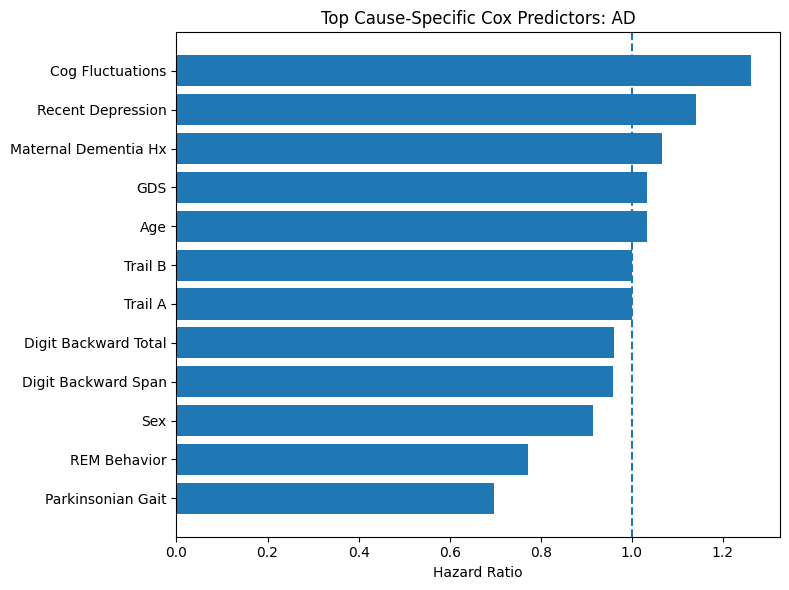

Saved: ..\output\survival\top_cause_specific_cox_predictors_PD_LBD_clinical.png


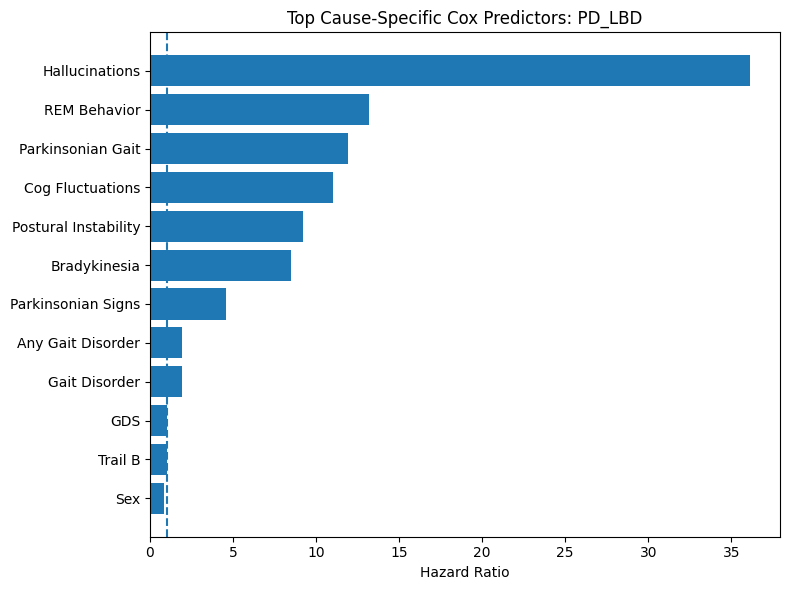

Saved: ..\output\survival\top_cause_specific_cox_predictors_Vascular_clinical.png


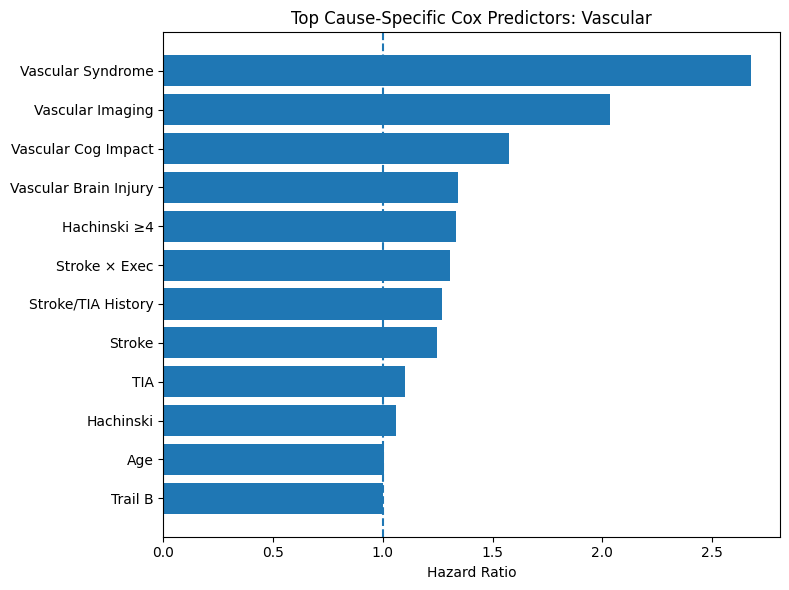

In [30]:
for outcome, cph in cause_models.items():
    hr_table = cph.summary[["exp(coef)", "p"]].copy()
    hr_table = hr_table.rename(columns={
        "exp(coef)": "hazard_ratio",
        "p": "p_value"
    })

    hr_table = hr_table.reset_index()
    hr_table = hr_table.rename(columns={hr_table.columns[0]: "feature"})

    hr_table = hr_table.loc[
        hr_table["feature"].apply(keep_survival_display_feature)
    ].copy()

    hr_table = (
        hr_table
        .sort_values("p_value")
        .head(12)
        .sort_values("hazard_ratio")
        .copy()
    )

    hr_table["feature_label"] = hr_table["feature"].apply(surv_label)

    plt.figure(figsize=(8, 6))
    plt.barh(hr_table["feature_label"], hr_table["hazard_ratio"])
    plt.axvline(1.0, linestyle="--")
    plt.xlabel("Hazard Ratio")
    plt.title(f"Top Cause-Specific Cox Predictors: {outcome}")
    plt.tight_layout()
    save_survival_fig(f"top_cause_specific_cox_predictors_{outcome}_clinical.png")
    plt.show()

In [31]:
# CDRSUM vs no-CDRSUM sensitivity analysis

def prep_for_cox(df, features, duration_col="time_to_event", event_col="event_flag"):
    tmp = df[[duration_col, event_col] + [c for c in features if c in df.columns]].copy()

    for col in tmp.columns:
        if col in [duration_col, event_col]:
            continue

        tmp[col] = pd.to_numeric(tmp[col], errors="coerce")

        if tmp[col].notna().sum() == 0:
            tmp[col] = 0
        else:
            tmp[col] = tmp[col].fillna(tmp[col].median())

    return tmp


base_features_with_cdr = [c for c in ANY_DEMENTIA_FEATURES if c in model_df.columns]
base_features_no_cdr = [f for f in base_features_with_cdr if f != "CDRSUM"]


def fit_compare_model(df, event_name=None):
    tmp = df.copy()

    if event_name is None:
        tmp["event_flag"] = tmp["event_any_dementia"].astype(int)
        model_label = "AnyDementia"
    else:
        tmp["event_flag"] = (tmp["event_type"] == event_name).astype(int)
        model_label = event_name

    df_with = prep_for_cox(tmp, base_features_with_cdr, event_col="event_flag")
    cph_with = CoxPHFitter(penalizer=0.1)
    cph_with.fit(df_with, duration_col="time_to_event", event_col="event_flag")

    df_no = prep_for_cox(tmp, base_features_no_cdr, event_col="event_flag")
    cph_no = CoxPHFitter(penalizer=0.1)
    cph_no.fit(df_no, duration_col="time_to_event", event_col="event_flag")

    return {
        "label": model_label,
        "with_cdr": cph_with,
        "without_cdr": cph_no,
        "df_with": df_with,
        "df_no": df_no
    }


sensitivity_results = {}
for outcome in [None, "AD", "PD_LBD", "Vascular"]:
    res = fit_compare_model(model_df, outcome)
    sensitivity_results[res["label"]] = res

summary_rows = []
for label, res in sensitivity_results.items():
    summary_rows.append({
        "model": label,
        "concordance_with_cdr": res["with_cdr"].concordance_index_,
        "concordance_without_cdr": res["without_cdr"].concordance_index_,
        "partial_AIC_with_cdr": res["with_cdr"].AIC_partial_,
        "partial_AIC_without_cdr": res["without_cdr"].AIC_partial_
    })

sensitivity_summary = pd.DataFrame(summary_rows)
display(sensitivity_summary)

,model,concordance_with_cdr,concordance_without_cdr,partial_AIC_with_cdr,partial_AIC_without_cdr
0,AnyDementia,0.856466,0.856466,86589.859409,86589.859409
1,AD,0.856199,0.856199,75682.649091,75682.649091
2,PD_LBD,0.941225,0.941225,10867.963182,10867.963182
3,Vascular,0.882037,0.882037,4613.258006,4613.258006


# Cross-etiology heatmap

In [32]:
# Cross-etiology factor comparison heatmap

heatmap_models = {
    "AD": sensitivity_results["AD"]["with_cdr"],
    "PD_LBD": sensitivity_results["PD_LBD"]["with_cdr"],
    "Vascular": sensitivity_results["Vascular"]["with_cdr"]
}

predictors_of_interest = [
    "NACCAGE","SEX","EDUC",
    "DEP2YRS","NACCGDS",
    "DIABETES","HYPERTEN","HYPERCHO","CVAFIB",
    "CBSTROKE","CBTIA","STROKE_TIA_ANY",
    "CVD","VASC","CVDCOG","CVDIMAG",
    "IMAGMWMH","IMAGEWMH",
    "FOCLSYM","FOCLSIGN",
    "HACHIN","HACHIN_GE_4","HACHIN_GE_7",
    "POSTINST","VASC_MED_COUNT","GAIT_ANY",
    "STROKDEC","STROKMUL","STROKE_x_EXEC",
    "COGFLUC","BEVHALL","BEREM","PARKSIGN","BRADY",
    #"RESTTRL","RESTTRR","RIGIDL","RIGIDR","SLOWINGL","SLOWINGR",
    "PARKGAIT",
    "TRAILB","DIGBACCT",
    #"ANIMALS",
    "NACCMOM","NACCDAD"
]

heatmap_data = pd.DataFrame(index=predictors_of_interest)

for label, model in heatmap_models.items():
    vals = []
    for pred in predictors_of_interest:
        if pred in model.summary.index:
            vals.append(model.summary.loc[pred, "coef"])
        else:
            vals.append(np.nan)
    heatmap_data[label] = vals

display(heatmap_data)

,AD,PD_LBD,Vascular
NACCAGE,0.032522,0.001690,0.006688
SEX,-0.088514,-0.186623,-0.026786
EDUC,-0.001172,0.002540,-0.001419
DEP2YRS,0.131892,0.107151,0.050171
NACCGDS,0.032596,0.033588,0.012881
DIABETES,-0.034903,-0.040799,0.063384
HYPERTEN,0.004655,-0.032467,0.060875
HYPERCHO,0.021811,0.002471,0.029728
CVAFIB,0.039027,0.061795,0.098769
CBSTROKE,0.017387,-0.028282,0.219289


Saved: ..\output\survival\cross_Etiology_Predictor_Comparison_clinical.png


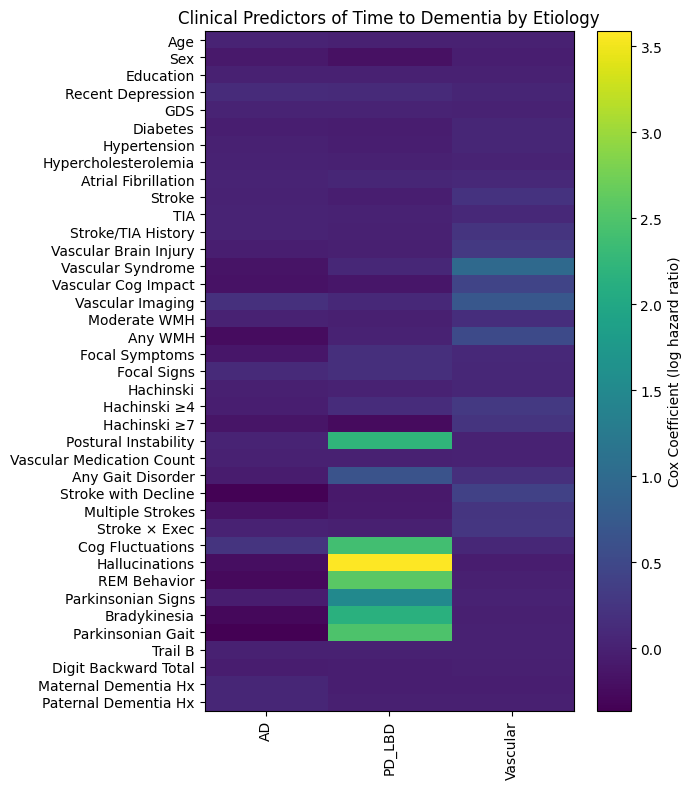

In [33]:
plt.figure(figsize=(7, 8))

plot_data = heatmap_data.copy()
plot_data.index = [surv_label(x) for x in plot_data.index]
plot_data.columns = [surv_label(x) for x in plot_data.columns]

im = plt.imshow(plot_data.values, aspect="auto")
plt.colorbar(im, label="Cox Coefficient (log hazard ratio)")

plt.xticks(range(len(plot_data.columns)), plot_data.columns, rotation=90)
plt.yticks(range(len(plot_data.index)), plot_data.index)
plt.title("Clinical Predictors of Time to Dementia by Etiology")
plt.tight_layout()
save_survival_fig("cross_Etiology_Predictor_Comparison_clinical.png")
plt.show()

3) vascular burden index

Cell below — Building vascular burden index

In [34]:
# Vascular Burden Index — cross-validated to prevent circularity
# Research basis: Pagan 1984 (International Economic Review) identified the
# "generated regressors" problem; Murphy & Topel 1985 showed standard errors
# are understated when predicted values are used as covariates.
# Fix: derive VBI using out-of-fold predictions so the VBI never sees
# the same data it was trained on.

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression

vascular_candidates = [
    "CBSTROKE", "diabetes_any", "htn_any", "hyperchol_any",
    "afib_any", "sleep_apnea_any", "CVDSIGNS", "POSTINST"
]

vascular_features = [c for c in vascular_candidates if c in model_df.columns]
print("VBI features:", vascular_features)

vbi_df = model_df.copy()
vbi_df["vascular_target"] = (vbi_df["event_type"] == "Vascular").astype(int)

X_vbi = vbi_df[vascular_features].copy()
y_vbi = vbi_df["vascular_target"].copy()

# Fill missing
for col in X_vbi.columns:
    if pd.api.types.is_numeric_dtype(X_vbi[col]):
        X_vbi[col] = X_vbi[col].fillna(X_vbi[col].median())

# Cross-validated VBI: each fold's VBI is predicted by a model
# that NEVER saw that fold's outcome labels
vbi_scores = np.zeros(len(X_vbi))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for fold_train, fold_test in skf.split(X_vbi, y_vbi):
    vbi_model_fold = LogisticRegression(
        class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE
    )
    vbi_model_fold.fit(X_vbi.iloc[fold_train], y_vbi.iloc[fold_train])
    vbi_scores[fold_test] = vbi_model_fold.predict_proba(
        X_vbi.iloc[fold_test]
    )[:, 1]

vbi_df["vascular_burden_index"] = vbi_scores

print("Cross-validated VBI statistics:")
print(vbi_df["vascular_burden_index"].describe())

# Also fit a final model on all data for coefficient inspection
vbi_model_full = LogisticRegression(
    class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE
)
vbi_model_full.fit(X_vbi, y_vbi)

VBI features: ['CBSTROKE', 'POSTINST']
Cross-validated VBI statistics:
count    27052.000000
mean         0.452493
std          0.080666
min          0.034269
25%          0.437286
50%          0.438808
75%          0.442222
max          0.922361
Name: vascular_burden_index, dtype: float64


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

Cell below — Inspect vascular burden weights

In [35]:
vbi_coef = pd.DataFrame({
    "feature": X_vbi.columns,
    "coef": vbi_model_full.coef_[0]
}).sort_values("coef", ascending=False)
display(vbi_coef)

,feature,coef
0,CBSTROKE,1.341137
1,POSTINST,-1.400646


Cell below — Merge vascular burden into survival modeling

In [36]:
# adding VBI survival model

model_df = model_df.merge(
    vbi_df[["NACCID", "vascular_burden_index"]],
    on="NACCID",
    how="left"
)

if "vascular_burden_index_x" in model_df.columns:
    model_df["vascular_burden_index"] = model_df["vascular_burden_index_x"]
    drop_cols = [c for c in ["vascular_burden_index_x", "vascular_burden_index_y"] if c in model_df.columns]
    model_df = model_df.drop(columns=drop_cols)

print(model_df[["NACCID", "vascular_burden_index"]].head())

       NACCID  vascular_burden_index
0  NACC000011               0.437286
1  NACC000034               0.437286
2  NACC000067               0.436355
3  NACC000138               0.442222
4  NACC000144               0.442222


Cell below — Refit any-dementia Cox with vascular burden index

In [37]:
# any-dementia cox + vascular burden index

cox_features_plus_vbi = [
    "NACCAGE","SEX","EDUC",
    "NACCMMSE","CDRSUM","DEP2YRS","NACCGDS",
    "STROKE_TIA_ANY","HACHIN","VASC_MED_COUNT","GAIT_ANY",
    "vascular_burden_index"
]

cox_vbi_df = model_df[
    ["time_to_event", "event_any_dementia"] + [c for c in cox_features_plus_vbi if c in model_df.columns]
].copy()

for col in cox_vbi_df.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    cox_vbi_df[col] = pd.to_numeric(cox_vbi_df[col], errors="coerce")
    if cox_vbi_df[col].notna().sum() == 0:
        cox_vbi_df[col] = 0
    else:
        cox_vbi_df[col] = cox_vbi_df[col].fillna(cox_vbi_df[col].median())

cox_vbi = CoxPHFitter(penalizer=0.1)
cox_vbi.fit(cox_vbi_df, duration_col="time_to_event", event_col="event_any_dementia")

display(
    cox_vbi.summary[["coef", "exp(coef)", "se(coef)", "p"]]
    .sort_values("p")
    .head(20)
)

,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.469759,1.599608,0.006797,0.000000e+00
NACCMMSE,-0.161236,0.851091,0.005521,1.684662e-187
NACCAGE,0.030773,1.031252,0.001254,6.422256e-133
NACCGDS,0.040541,1.041374,0.004942,2.342972e-16
SEX,-0.165082,0.847825,0.023417,1.793206e-12
DEP2YRS,0.180732,1.198094,0.028072,1.208776e-10
EDUC,0.005126,1.005139,0.001776,3.905790e-03
STROKE_TIA_ANY,0.131658,1.140718,0.048588,6.734970e-03
VASC_MED_COUNT,0.013334,1.013424,0.008719,1.261736e-01


# Calibration assessment (required by TRIPOD guidelines)

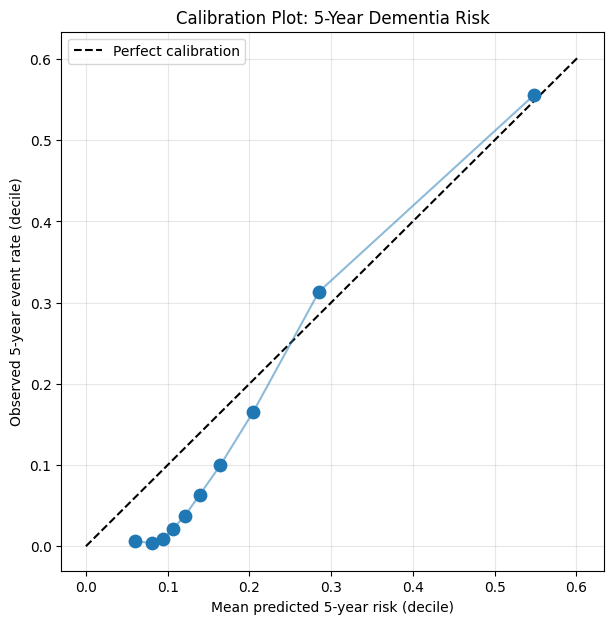

ICI (Integrated Calibration Index): 0.0673
E50 (Median absolute error):        0.0722
E90 (90th percentile error):         0.0888
(Lower = better; ICI < 0.05 is generally good)


In [38]:
# Calibration assessment for the any-dementia Cox model
# Research basis: TRIPOD+AI (2024) requires calibration metrics.
# Austin, Harrell & van Klaveren 2020 (Statistics in Medicine)
# recommend graphical calibration + ICI + E50 + E90.

from lifelines.calibration import survival_probability_calibration
import matplotlib.pyplot as plt

# 5-year calibration
t_eval = 5.0

# Predicted 5-year survival probability
surv_pred_5y = cox_vbi.predict_survival_function(
    cox_vbi_df.drop(columns=["time_to_event", "event_any_dementia"]),
    times=[t_eval]
).T.iloc[:, 0].values

# Predicted 5-year event probability
pred_risk_5y = 1.0 - surv_pred_5y

# Observed events (binary: did event happen before t_eval?)
observed_event_5y = (
    (cox_vbi_df["time_to_event"] <= t_eval) &
    (cox_vbi_df["event_any_dementia"] == 1)
).astype(int).values

# Simple calibration plot: predicted vs observed by decile
n_groups = 10
sorted_idx = np.argsort(pred_risk_5y)
group_size = len(pred_risk_5y) // n_groups

pred_means = []
obs_means = []

for g in range(n_groups):
    start = g * group_size
    end = (g + 1) * group_size if g < n_groups - 1 else len(pred_risk_5y)
    idx = sorted_idx[start:end]
    pred_means.append(np.mean(pred_risk_5y[idx]))
    obs_means.append(np.mean(observed_event_5y[idx]))

plt.figure(figsize=(7, 7))
plt.plot([0, max(pred_means) * 1.1], [0, max(pred_means) * 1.1],
         "k--", label="Perfect calibration")
plt.scatter(pred_means, obs_means, s=80, zorder=5)
plt.plot(pred_means, obs_means, alpha=0.5)
plt.xlabel("Mean predicted 5-year risk (decile)")
plt.ylabel("Observed 5-year event rate (decile)")
plt.title("Calibration Plot: 5-Year Dementia Risk")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ICI: Integrated Calibration Index
# = mean absolute difference between predicted and smoothed observed
from sklearn.isotonic import IsotonicRegression
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(pred_risk_5y, observed_event_5y)
smoothed_obs = iso.predict(pred_risk_5y)
ICI = np.mean(np.abs(pred_risk_5y - smoothed_obs))
E50 = np.median(np.abs(pred_risk_5y - smoothed_obs))
E90 = np.percentile(np.abs(pred_risk_5y - smoothed_obs), 90)

print(f"ICI (Integrated Calibration Index): {ICI:.4f}")
print(f"E50 (Median absolute error):        {E50:.4f}")
print(f"E90 (90th percentile error):         {E90:.4f}")
print("(Lower = better; ICI < 0.05 is generally good)")

# Add time-dependent AUC alongside C-index

In [39]:
# Time-dependent AUC at clinically relevant horizons
# Research basis: Heagerty & Zheng 2005; Hartman et al. 2023 (Statistics in
# Medicine) showed C-index is unreliable at <1% event rates.
# Uno's IPCW C-statistic is censoring-distribution-independent.

from sklearn.metrics import roc_auc_score

eval_times = [3, 5, 7, 10]

for t_eval in eval_times:
    # Binary outcome at this horizon
    event_by_t = (
        (cox_vbi_df["time_to_event"] <= t_eval) &
        (cox_vbi_df["event_any_dementia"] == 1)
    ).astype(int)

    # Only include subjects who are either:
    # - observed to have event by t_eval, OR
    # - censored AFTER t_eval (so we know they were event-free at t_eval)
    evaluable = (
        (event_by_t == 1) |
        (cox_vbi_df["time_to_event"] > t_eval)
    )

    if evaluable.sum() < 50 or event_by_t[evaluable].sum() < 10:
        print(f"  {t_eval}y: insufficient events for reliable AUC")
        continue

    pred_risk = 1.0 - cox_vbi.predict_survival_function(
        cox_vbi_df.loc[evaluable].drop(columns=["time_to_event", "event_any_dementia"]),
        times=[t_eval]
    ).T.iloc[:, 0].values

    auc = roc_auc_score(event_by_t[evaluable], pred_risk)
    n_events = event_by_t[evaluable].sum()
    print(f"  {t_eval}y AUC: {auc:.3f}  (n_events={n_events}, n_evaluable={evaluable.sum()})")

  3y AUC: 0.898  (n_events=2535, n_evaluable=18404)
  5y AUC: 0.899  (n_events=3454, n_evaluable=14390)
  7y AUC: 0.900  (n_events=3978, n_evaluable=11083)
  10y AUC: 0.905  (n_events=4412, n_evaluable=8297)


Cell below — Survival curves stratified by vascular burden tertiles

Saved: ..\output\survival\dementia-Free_Survival_by_Vascular_Burden_Index.png


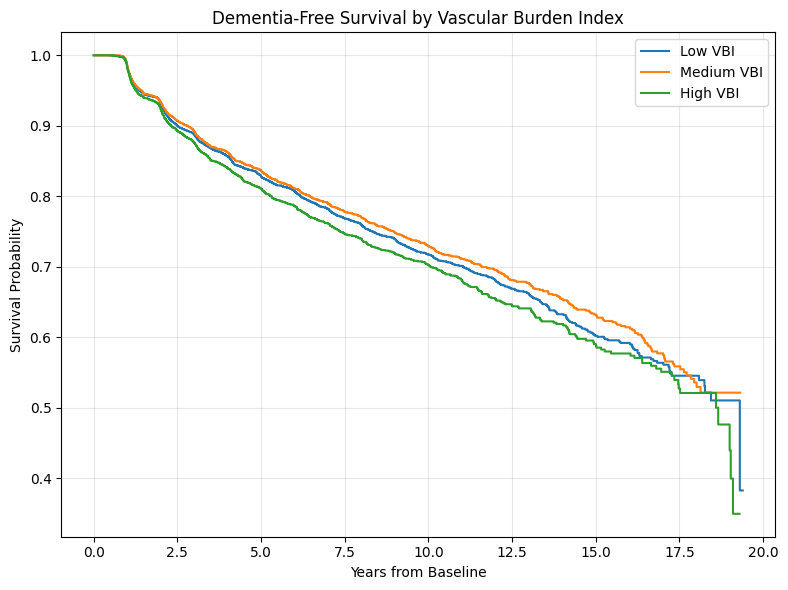

In [40]:
# Kaplan-Meier curves by VBI tertiles

km_vbi_df = model_df[["time_to_event", "event_any_dementia", "vascular_burden_index"]].dropna().copy()
km_vbi_df["vbi_group"] = pd.qcut(
    km_vbi_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

plt.figure(figsize=(8, 6))
kmf = KaplanMeierFitter()

for grp in ["Low VBI", "Medium VBI", "High VBI"]:
    tmp = km_vbi_df[km_vbi_df["vbi_group"] == grp]
    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot(ci_show=False)

plt.title("Dementia-Free Survival by Vascular Burden Index")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
save_survival_fig("dementia-Free_Survival_by_Vascular_Burden_Index.png")
plt.show()

# Stratified competing-risk plot

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


Saved: ..\output\survival\cumulative_Incidence_of_AD_by_Vascular_Burden.png


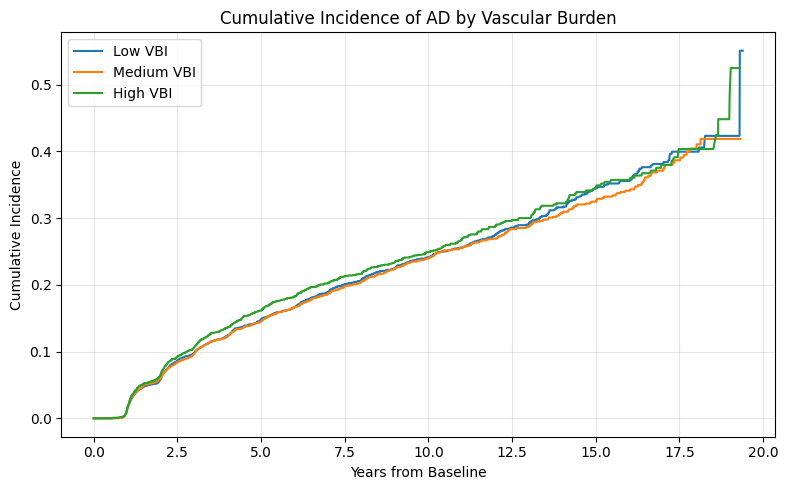

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


Saved: ..\output\survival\cumulative_Incidence_of_PD_LBD_by_Vascular_Burden.png


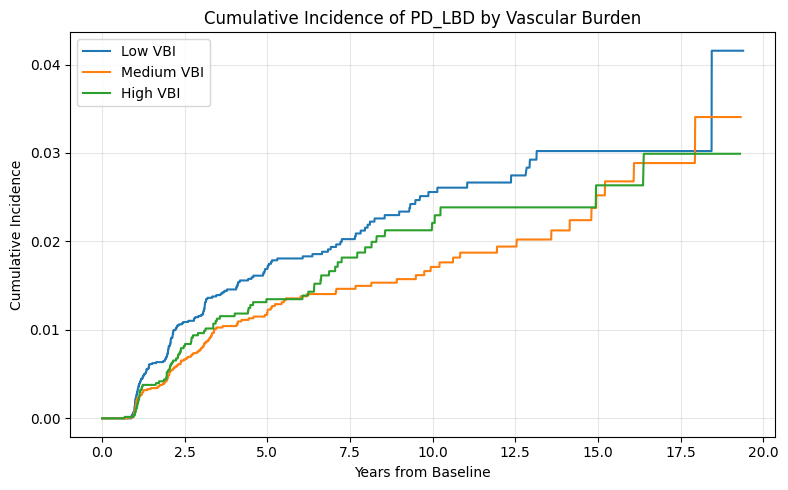

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


Saved: ..\output\survival\cumulative_Incidence_of_Vascular_by_Vascular_Burden.png


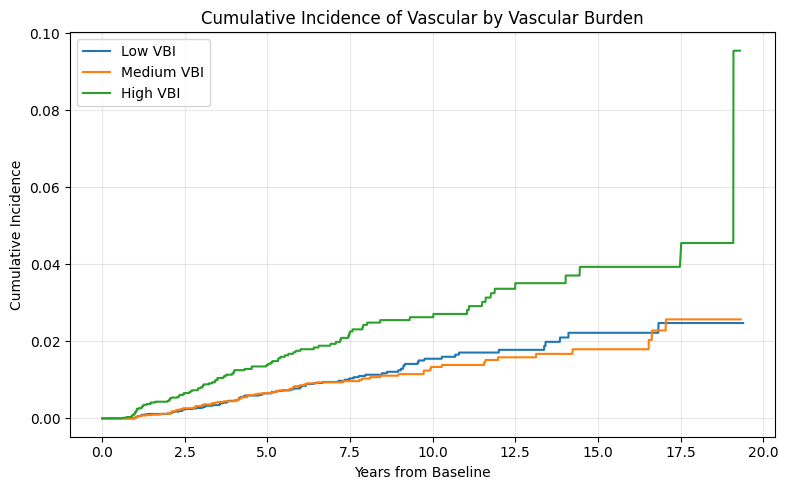

In [41]:
# Stratified competing-risk cumulative incidence by VBI tertile

# Merge VBI into competing-risk dataframe
if "vascular_burden_index" not in cr_df.columns:
    cr_df = cr_df.merge(
        model_df[["NACCID", "vascular_burden_index"]].drop_duplicates(),
        on="NACCID",
        how="left"
    )

cr_df["vbi_group"] = pd.qcut(
    cr_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

event_map = {"AD": 1, "PD_LBD": 2, "Vascular": 3}

for event_name, event_code in event_map.items():
    plt.figure(figsize=(8, 5))

    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        plt.plot(
            ajf.cumulative_density_.index,
            ajf.cumulative_density_.iloc[:, 0],
            label=grp
        )

    plt.title(f"Cumulative Incidence of {event_name} by Vascular Burden")
    plt.xlabel("Years from Baseline")
    plt.ylabel("Cumulative Incidence")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_survival_fig(f"cumulative_Incidence_of_{event_name}_by_Vascular_Burden.png")
    plt.show()

In [42]:
milestone_years = [5, 10, 15]
rows = []

for event_name, event_code in event_map.items():
    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        vals = {}
        for yr in milestone_years:
            idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
            vals[f"{yr}y"] = float(ajf.cumulative_density_.iloc[idx, 0])

        rows.append({
            "event": event_name,
            "vbi_group": grp,
            **vals
        })

cif_vbi_table = pd.DataFrame(rows)
display(cif_vbi_table)

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is rand

,event,vbi_group,5y,10y,15y
0,AD,Low VBI,0.148006,0.241700,0.345329
1,AD,Medium VBI,0.144934,0.240327,0.324574
2,AD,High VBI,0.161490,0.248946,0.343916
3,PD_LBD,Low VBI,0.016882,0.025582,0.030213
4,PD_LBD,Medium VBI,0.011892,0.017116,0.025210
5,PD_LBD,High VBI,0.013471,0.022097,0.026345
6,Vascular,Low VBI,0.006480,0.015489,0.022224
7,Vascular,Medium VBI,0.006599,0.013350,0.017951
8,Vascular,High VBI,0.013818,0.026274,0.039348


4) Bootstrap uncertainty-aware survival prediction
Cell below — Bootstrap Cox ensemble


In [ ]:
# bootstrap ensemble for 5-year risk prediction uncertainty

N_BOOT = 1000  # was 30; minimum for valid 95% CIs (Efron & Tibshirani 1993)
PRED_HORIZON_YEARS = 5.0

boot_features = [
    "NACCAGE","SEX","EDUC",
    "NACCMMSE","CDRSUM","DEP2YRS","NACCGDS",
    "STROKE_TIA_ANY","HACHIN","VASC_MED_COUNT","GAIT_ANY",
    "vascular_burden_index"
]

boot_df = model_df[
    ["NACCID", "time_to_event", "event_any_dementia"] + [c for c in boot_features if c in model_df.columns]
].copy()

for col in boot_df.columns:
    if col in ["NACCID", "time_to_event", "event_any_dementia"]:
        continue
    boot_df[col] = pd.to_numeric(boot_df[col], errors="coerce")
    if boot_df[col].notna().sum() == 0:
        boot_df[col] = 0
    else:
        boot_df[col] = boot_df[col].fillna(boot_df[col].median())

fit_cols = [c for c in boot_df.columns if c != "NACCID"]
boot_feature_cols = [c for c in fit_cols if c not in ["time_to_event", "event_any_dementia"]]

risk_preds = []

for b in range(N_BOOT):
    sample_idx = np.random.choice(len(boot_df), size=len(boot_df), replace=True)
    boot_sample = boot_df.iloc[sample_idx][fit_cols].copy()

    cph_b = CoxPHFitter(penalizer=0.1)
    cph_b.fit(
        boot_sample,
        duration_col="time_to_event",
        event_col="event_any_dementia"
    )

    surv_funcs = cph_b.predict_survival_function(
        boot_df[boot_feature_cols],
        times=[PRED_HORIZON_YEARS]
    )

    risk_5y = 1.0 - surv_funcs.T.iloc[:, 0].values
    risk_preds.append(risk_5y)

risk_preds = np.vstack(risk_preds)

print("risk_preds shape:", risk_preds.shape)
print("n patients:", len(boot_df))
print("n feature cols:", len(boot_feature_cols))

Cell below — Compute uncertainty + confidence

In [ ]:
# uncertainty / confidence scores

uncertainty_df = boot_df[["NACCID", "time_to_event", "event_any_dementia"]].copy()
uncertainty_df["risk_5y_mean"] = risk_preds.mean(axis=0)
uncertainty_df["risk_5y_std"]  = risk_preds.std(axis=0)
uncertainty_df["risk_5y_p10"]  = np.percentile(risk_preds, 10, axis=0)
uncertainty_df["risk_5y_p90"]  = np.percentile(risk_preds, 90, axis=0)

# simple confidence score
max_std = uncertainty_df["risk_5y_std"].max()
uncertainty_df["confidence_score"] = 1 - (uncertainty_df["risk_5y_std"] / max_std)
uncertainty_df["confidence_score"] = uncertainty_df["confidence_score"].clip(0, 1)

display(uncertainty_df.head())
display(uncertainty_df.describe())

,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
0,NACC000011,3.296372,0,0.075787,0.002407,0.072684,0.078949,0.969609
1,NACC000034,5.848049,1,0.147383,0.003759,0.142587,0.152512,0.952541
2,NACC000067,2.088980,0,0.201608,0.028947,0.161853,0.236991,0.634561
3,NACC000138,1.043121,0,0.057041,0.002057,0.054235,0.059561,0.974036
4,NACC000144,8.487337,0,0.179534,0.012756,0.161682,0.195621,0.838964


,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
count,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000
mean,5.117712,0.179321,0.180477,0.008094,0.170137,0.191237,0.897813
std,4.214639,0.383628,0.150562,0.008987,0.142320,0.160647,0.113448
min,0.109514,0.000000,0.017399,0.000000,0.015989,0.018766,0.000000
25%,1.938398,0.000000,0.093194,0.003024,0.088732,0.097443,0.888037
50%,3.786448,0.000000,0.128286,0.004645,0.121418,0.134352,0.941364
75%,7.124572,0.000000,0.202529,0.008869,0.190617,0.214462,0.961825
max,19.392197,1.000000,1.000000,0.079213,1.000000,1.000000,1.000000


Cell below — Scatter plot: risk vs uncertainty

Saved: ..\output\survival\risk_vs_Prediction_Uncertainty.png


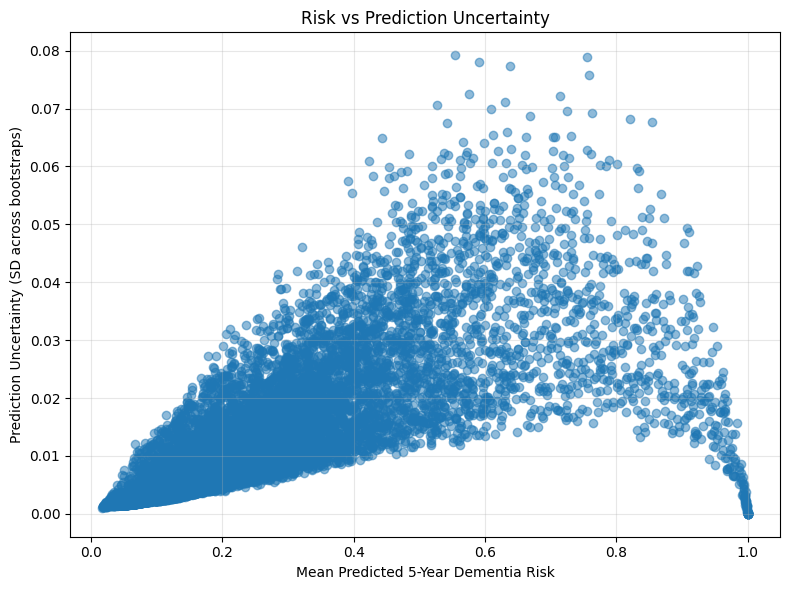

In [ ]:
# risk vs uncertainty plot

plt.figure(figsize=(8, 6))
plt.scatter(
    uncertainty_df["risk_5y_mean"],
    uncertainty_df["risk_5y_std"],
    alpha=0.5
)
plt.xlabel("Mean Predicted 5-Year Dementia Risk")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Risk vs Prediction Uncertainty")
plt.grid(True, alpha=0.3)
save_survival_fig("risk_vs_Prediction_Uncertainty.png")
plt.show()

Cell below — Identify high-uncertainty cases

In [ ]:
# flag high-uncertainty cases

uncert_thresh = uncertainty_df["risk_5y_std"].quantile(0.80)
uncertainty_df["high_uncertainty"] = (uncertainty_df["risk_5y_std"] >= uncert_thresh).astype(int)

print("High-uncertainty threshold:", uncert_thresh)
print(uncertainty_df["high_uncertainty"].value_counts())

display(
    uncertainty_df.sort_values("risk_5y_std", ascending=False).head(15)
)

High-uncertainty threshold: 0.010860831648827816
high_uncertainty
0    21641
1     5411
Name: count, dtype: int64


,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score,high_uncertainty
58,NACC001959,3.485284,0,0.553921,0.079213,0.444052,0.652058,0.000000,1
15201,NACC561917,6.518823,0,0.754966,0.078959,0.666990,0.872737,0.003196,1
8244,NACC307329,1.111567,1,0.590619,0.078134,0.507620,0.708022,0.013620,1
8307,NACC309605,8.640657,0,0.637576,0.077372,0.553836,0.754348,0.023237,1
11992,NACC444257,1.075975,1,0.758627,0.075727,0.675490,0.870826,0.044002,1
7776,NACC289818,1.155373,1,0.575522,0.072530,0.499552,0.683116,0.084362,1
14979,NACC553391,0.966461,1,0.714079,0.072130,0.617195,0.802442,0.089414,1
16754,NACC618927,0.999316,1,0.631051,0.071147,0.555324,0.736399,0.101821,1
8060,NACC300648,5.002053,0,0.526478,0.070698,0.429763,0.614861,0.107496,1
7511,NACC280530,1.927447,1,0.609484,0.069937,0.535384,0.712884,0.117097,1


5) Uncertain-case phenotype analysis
Cell below — Merge uncertainty back to clinical variables

In [ ]:
# merge uncertainty back for phenotype analysis

analysis_df = model_df.merge(
    uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score", "high_uncertainty"]],
    on="NACCID",
    how="left"
)

print(analysis_df.shape)

(27052, 87)


Cell below — Compare high- vs low-uncertainty groups

In [ ]:
# phenotype comparison: high vs low uncertainty 

compare_vars = [
    "NACCAGE","EDUC","NACCMMSE","CDRSUM","NACCGDS",
    "DIABETES","HYPERTEN","HYPERCHO","CVAFIB",
    "CBSTROKE","CBTIA","STROKE_TIA_ANY",
    "CVD","VASC","HACHIN","VASC_MED_COUNT","GAIT_ANY",
    "vascular_burden_index"
]

rows = []
for col in compare_vars:
    if col not in analysis_df.columns:
        continue

    tmp0 = analysis_df.loc[analysis_df["high_uncertainty"] == 0, col]
    tmp1 = analysis_df.loc[analysis_df["high_uncertainty"] == 1, col]

    rows.append({
        "variable": col,
        "low_uncert_mean": pd.to_numeric(tmp0, errors="coerce").mean(),
        "high_uncert_mean": pd.to_numeric(tmp1, errors="coerce").mean(),
        "difference": pd.to_numeric(tmp1, errors="coerce").mean() - pd.to_numeric(tmp0, errors="coerce").mean()
    })

uncert_compare = pd.DataFrame(rows).sort_values("difference", ascending=False)
display(uncert_compare)

,variable,low_uncert_mean,high_uncert_mean,difference
0,NACCAGE,69.855691,74.918499,5.062809
4,NACCGDS,1.364315,3.158374,1.794060
3,CDRSUM,0.250520,1.700795,1.450275
14,HACHIN,0.611469,1.451998,0.840529
1,EDUC,15.991128,16.534467,0.543339
15,VASC_MED_COUNT,1.263528,1.682683,0.419156
9,CBSTROKE,0.017686,0.209123,0.191437
11,STROKE_TIA_ANY,0.035442,0.189059,0.153617
6,HYPERTEN,0.489256,0.627230,0.137974
10,CBTIA,0.044929,0.165021,0.120092


Cell below — Event-type breakdown inside high-uncertainty cases

In [ ]:
# finding what types of events appear in high-uncertainty cases

event_uncert_table = pd.crosstab(
    analysis_df["event_type"],
    analysis_df["high_uncertainty"],
    normalize="columns"
)

display(event_uncert_table)

high_uncertainty,0,1
event_type,,
AD,0.101012,0.375531
Censored,0.885911,0.559786
PD_LBD,0.007162,0.040473
Vascular,0.005915,0.024210


Using Cox model: cox_vbi
Saved: ..\output\survival\dementia_Risk_Landscape_contrast.png


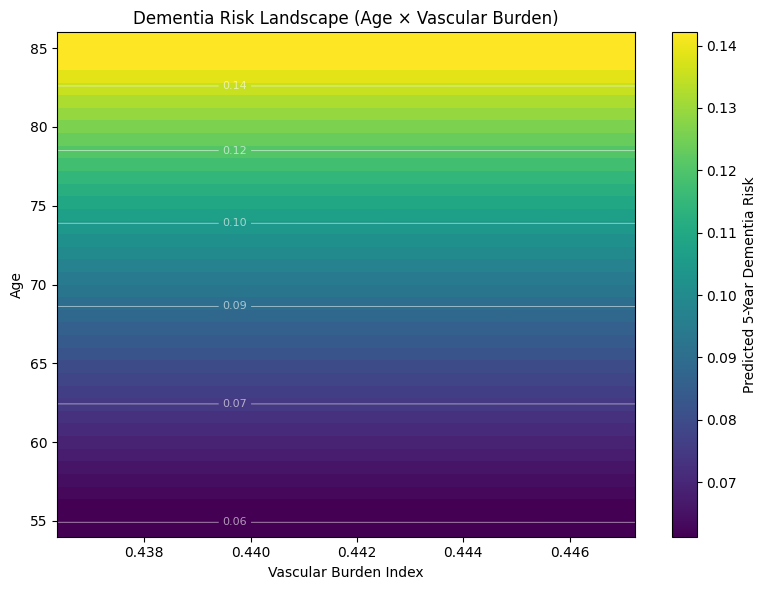

In [ ]:
# Dementia Risk Landscape: Age x Vascular Burden

# Identifying the Cox model with vascular burden
main_cph = None
for name in ["cox_vbi", "cph_vbi", "cox_ph", "cox_model"]:
    if name in globals():
        main_cph = globals()[name]
        print("Using Cox model:", name)
        break

if main_cph is None:
    raise ValueError("Could not find the Cox model with vascular_burden_index")

# Columns used by the Cox model
model_cols = list(main_cph.params_.index)

reference = {}
for col in model_cols:
    if col in analysis_df.columns:
        reference[col] = analysis_df[col].median()
    else:
        reference[col] = 0

# using most common value for sex
if "SEX" in analysis_df.columns:
    reference["SEX"] = analysis_df["SEX"].mode()[0]

# Grid ranges
age_grid = np.linspace(
    analysis_df["NACCAGE"].quantile(0.05),
    analysis_df["NACCAGE"].quantile(0.95),
    40
)

vbi_grid = np.linspace(
    analysis_df["vascular_burden_index"].quantile(0.05),
    analysis_df["vascular_burden_index"].quantile(0.95),
    40
)

# Build prediction grid
grid_rows = []

for age in age_grid:
    for vbi in vbi_grid:
        row = reference.copy()
        if "NACCAGE" in row:
            row["NACCAGE"] = age
        if "vascular_burden_index" in row:
            row["vascular_burden_index"] = vbi
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)[model_cols]

for col in grid_df.columns:
    grid_df[col] = pd.to_numeric(grid_df[col], errors="coerce").fillna(0)

# Predict 5-year risk
surv = main_cph.predict_survival_function(grid_df, times=[5.0])
risk_5y = 1 - surv.T.iloc[:, 0].values

risk_matrix = risk_5y.reshape(len(age_grid), len(vbi_grid))

plt.figure(figsize=(8,6))

# improved contrast
vmin = np.quantile(risk_matrix, 0.05)
vmax = np.quantile(risk_matrix, 0.95)

im = plt.imshow(
    risk_matrix,
    aspect="auto",
    origin="lower",
    extent=[
        vbi_grid.min(),
        vbi_grid.max(),
        age_grid.min(),
        age_grid.max()
    ],
    vmin=vmin,
    vmax=vmax,
    cmap="viridis"
)

# optional contour lines
X, Y = np.meshgrid(vbi_grid, age_grid)
contours = plt.contour(
    X, Y, risk_matrix,
    colors="white",
    linewidths=0.6,
    alpha=0.6
)
plt.clabel(contours, inline=True, fontsize=8, fmt="%.2f")

plt.colorbar(im, label="Predicted 5-Year Dementia Risk")

plt.xlabel("Vascular Burden Index")
plt.ylabel("Age")
plt.title("Dementia Risk Landscape (Age × Vascular Burden)")
save_survival_fig("dementia_Risk_Landscape_contrast.png")

plt.show()

6)  diagreement analysis hook

In [ ]:
# classifier vs observed outcome disordance
# compares classifier predictions to observed event_type.

clf_preds = pd.read_csv("../output/classifier_predictions.csv")

if "clf_preds" in globals():
    dis_df = analysis_df.copy()

    dis_df = dis_df.merge(clf_preds[["NACCID", "predicted_class"]], on="NACCID", how="left")

    dis_df["predicted_class_norm"] = dis_df["predicted_class"].replace({
        "NoDementia_Hy": "Censored",
        "NoDementia_5y": "Censored"
    })

    dis_df["model_disagreement"] = (
        dis_df["predicted_class_norm"].notna() &
        (dis_df["predicted_class_norm"] != dis_df["event_type"])
    ).astype(int)

    print(dis_df["model_disagreement"].value_counts(dropna=False))

    display(
        pd.crosstab(dis_df["event_type"], dis_df["model_disagreement"], normalize="columns")
    )

    display(
        dis_df.loc[dis_df["model_disagreement"] == 1,
                   ["NACCID", "event_type", "predicted_class", "risk_5y_mean", "risk_5y_std", "confidence_score"]]
        .head(20)
    )
else:
    print("clf_preds not found. Skipping disagreement analysis.")

model_disagreement
0    26483
1      569
Name: count, dtype: int64


model_disagreement,0,1
event_type,,
AD,0.146131,0.611599
Censored,0.832610,0.265378
PD_LBD,0.012914,0.056239
Vascular,0.008345,0.066784


,NACCID,event_type,predicted_class,risk_5y_mean,risk_5y_std,confidence_score
13,NACC000333,AD,NoDementia_Hy,0.319831,0.014751,0.813774
166,NACC005498,AD,NoDementia_Hy,0.138367,0.004137,0.947768
222,NACC007474,AD,NoDementia_Hy,0.163928,0.004970,0.937254
320,NACC011190,AD,NoDementia_Hy,0.077098,0.002262,0.971442
361,NACC012829,AD,NoDementia_Hy,0.209063,0.005784,0.926980
447,NACC016700,Censored,AD,0.239218,0.007439,0.906094
471,NACC017560,Censored,AD,0.152934,0.003422,0.956799
478,NACC017883,AD,NoDementia_Hy,0.073375,0.002119,0.973246
503,NACC018917,Vascular,NoDementia_Hy,0.132096,0.003599,0.954568
524,NACC019767,Censored,AD,0.299175,0.024477,0.690992


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Retrieving cause-specific models
def get_cause_models():
    models = {}

    if "cause_models" in globals():
        if isinstance(cause_models, dict):
            models = cause_models.copy()

    if "AD" not in models:
        if "cph_AD" in globals():
            models["AD"] = cph_AD
    if "PD_LBD" not in models:
        if "cph_PD" in globals():
            models["PD_LBD"] = cph_PD
        elif "cph_PD_LBD" in globals():
            models["PD_LBD"] = cph_PD_LBD
    if "Vascular" not in models:
        if "cph_VASC" in globals():
            models["Vascular"] = cph_VASC
        elif "cph_Vascular" in globals():
            models["Vascular"] = cph_Vascular

    return models

cause_model_map = get_cause_models()
print("Available cause-specific models:", list(cause_model_map.keys()))

Available cause-specific models: ['AD', 'PD_LBD', 'Vascular']


Step 1 — Etiology-specific risk curves

This produces the figure showing projected AD vs PD/LBD vs vascular risk over time.


In [ ]:
# Step 1: Etiology-specific risk curves

times = np.linspace(0.5, 20, 120)

# choosing source dataframe for prediction
if "model_df" in globals():
    pred_df_base = model_df.copy()
elif "analysis_df" in globals():
    pred_df_base = analysis_df.copy()
else:
    raise ValueError("Neither model_df nor analysis_df is available.")

risk_curve_summary = {}

for label, model in cause_model_map.items():
    model_cols = list(model.params_.index)

    pred_df = pred_df_base.copy()

    for col in model_cols:
        if col not in pred_df.columns:
            pred_df[col] = 0

    X_pred = pred_df[model_cols].copy()

    for col in X_pred.columns:
        X_pred[col] = pd.to_numeric(X_pred[col], errors="coerce").fillna(0)

    surv = model.predict_survival_function(X_pred, times=times)
    # mean cause-specific event probability over time
    mean_risk = (1 - surv).mean(axis=1)

    risk_curve_summary[label] = pd.Series(mean_risk.values, index=times)

risk_curve_df = pd.DataFrame(risk_curve_summary)
display(risk_curve_df.head())

,AD,PD_LBD,Vascular
0.500000,0.000104,0.000000,0.000000
0.663866,0.000674,0.000000,0.000041
0.827731,0.001712,0.000070,0.000082
0.991597,0.015363,0.000475,0.000333
1.155462,0.046462,0.000810,0.001185


Saved: ..\output\survival\etiology-Specific_Dementia_Risk_Curves.png


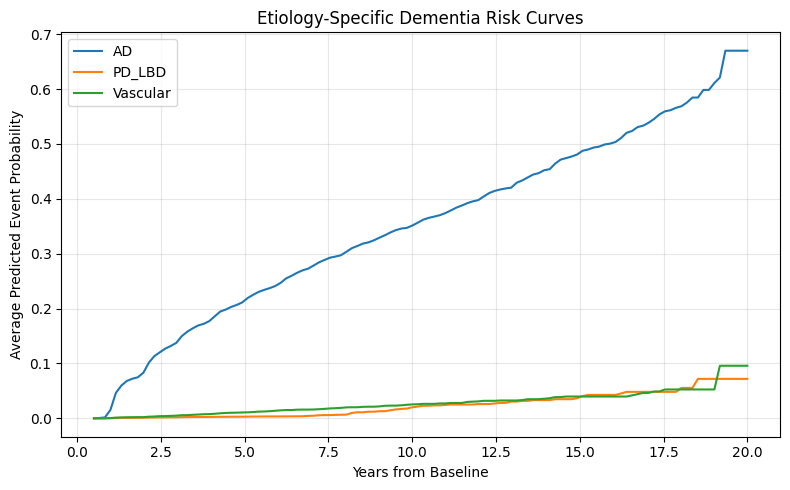

In [ ]:
plt.figure(figsize=(8, 5))

for label in ["AD", "PD_LBD", "Vascular"]:
    if label in risk_curve_df.columns:
        plt.plot(risk_curve_df.index, risk_curve_df[label], label=label)

plt.xlabel("Years from Baseline")
plt.ylabel("Average Predicted Event Probability")
plt.title("Etiology-Specific Dementia Risk Curves")
plt.legend()
plt.grid(True, alpha=0.3)
save_survival_fig("etiology-Specific_Dementia_Risk_Curves.png")
plt.show()

In [ ]:
milestone_years = [5, 10, 15]

etiology_risk_table = pd.DataFrame(index=milestone_years)

for label in risk_curve_df.columns:
    etiology_risk_table[label] = [
        float(risk_curve_df[label].iloc[np.argmin(np.abs(risk_curve_df.index - yr))])
        for yr in milestone_years
    ]

etiology_risk_table.index.name = "Years"
display(etiology_risk_table)

,AD,PD_LBD,Vascular
Years,,,
5,0.211190,0.003012,0.010691
10,0.351437,0.020123,0.025376
15,0.480791,0.036782,0.039751


Step 2 — Risk stratification survival curves


In [ ]:
# Step 2: Risk stratification groups

if "analysis_df" not in globals():
    if "model_df" in globals() and "uncertainty_df" in globals():
        analysis_df = model_df.merge(
            uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score"]],
            on="NACCID",
            how="left"
        )
    else:
        raise ValueError("Need analysis_df or both model_df and uncertainty_df.")

# creaing risk groups using tertiles
analysis_df["risk_group_3"] = pd.qcut(
    analysis_df["risk_5y_mean"],
    q=3,
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print(analysis_df["risk_group_3"].value_counts(dropna=False))

risk_group_3
Medium Risk    9018
Low Risk       9017
High Risk      9017
Name: count, dtype: int64


Saved: ..\output\survival\dementia-Free_Survival_by_Predicted_5-Year_Risk_Group.png


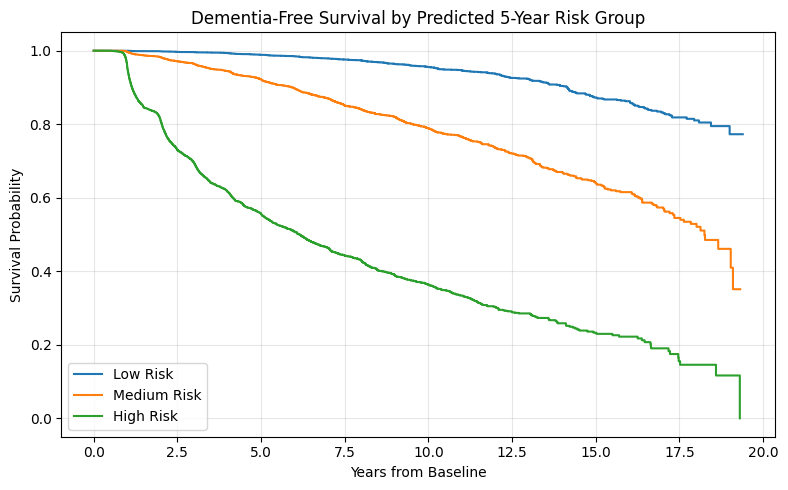

In [ ]:
plt.figure(figsize=(8, 5))
kmf = KaplanMeierFitter()

for grp in ["Low Risk", "Medium Risk", "High Risk"]:
    tmp = analysis_df[analysis_df["risk_group_3"] == grp].copy()

    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Dementia-Free Survival by Predicted 5-Year Risk Group")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
save_survival_fig("dementia-Free_Survival_by_Predicted_5-Year_Risk_Group.png")
plt.show()

In [ ]:
risk_group_summary = analysis_df.groupby("risk_group_3").agg(
    n=("NACCID", "count"),
    mean_predicted_5y_risk=("risk_5y_mean", "mean"),
    observed_event_rate=("event_any_dementia", "mean"),
    mean_followup=("time_to_event", "mean")
)

display(risk_group_summary)

C:\Users\branjan\AppData\Local\Temp\ipykernel_27004\1494596913.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  risk_group_summary = analysis_df.groupby("risk_group_3").agg(


,n,mean_predicted_5y_risk,observed_event_rate,mean_followup
risk_group_3,,,,
Low Risk,9017,0.080065,0.033714,6.376179
Medium Risk,9018,0.130695,0.113994,5.376833
High Risk,9017,0.330678,0.390263,3.600096


Step 3 — Explaining uncertainty

creating plots showing who becomes uncertain.

In [ ]:
# Step 3: Uncertainty explanation

needed_cols = ["risk_5y_std", "confidence_score"]
for c in needed_cols:
    if c not in analysis_df.columns:
        raise ValueError(f"{c} not found in analysis_df")

Saved: ..\output\survival\uncertainty_vs_Age.png


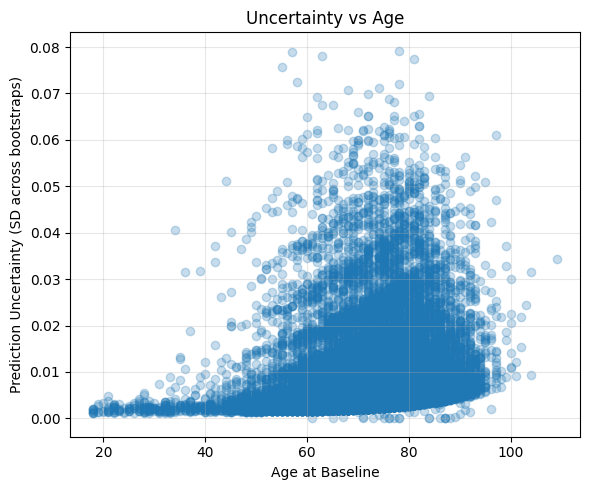

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["NACCAGE"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("Age at Baseline")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Age")
plt.grid(True, alpha=0.3)
save_survival_fig("uncertainty_vs_Age.png")
plt.show()

Saved: ..\output\survival\uncertainty_vs_Baseline_Cognitive_Impairment.png


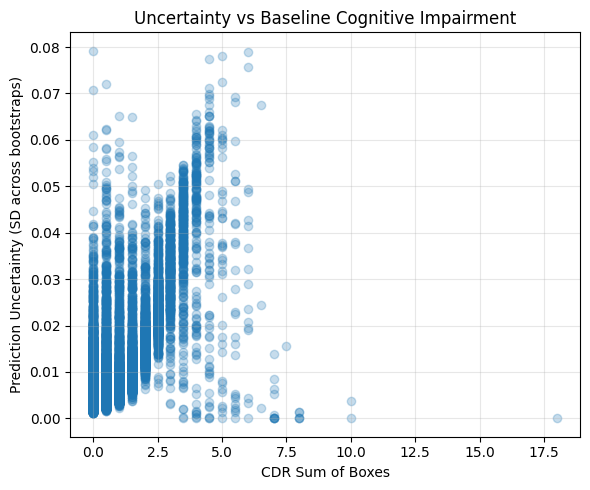

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["CDRSUM"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("CDR Sum of Boxes")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Baseline Cognitive Impairment")
plt.grid(True, alpha=0.3)
save_survival_fig("uncertainty_vs_Baseline_Cognitive_Impairment.png")
plt.show()

Saved: ..\output\survival\uncertainty_vs_Vascular_Burden.png


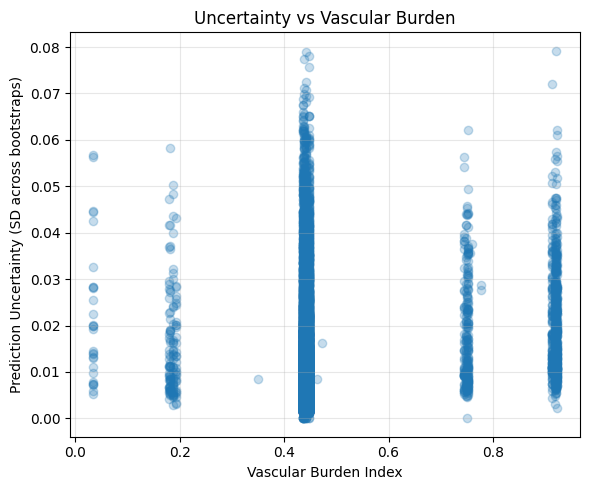

In [ ]:
if "vascular_burden_index" in analysis_df.columns:
    plt.figure(figsize=(6, 5))
    plt.scatter(
        analysis_df["vascular_burden_index"],
        analysis_df["risk_5y_std"],
        alpha=0.25
    )
    plt.xlabel("Vascular Burden Index")
    plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
    plt.title("Uncertainty vs Vascular Burden")
    plt.grid(True, alpha=0.3)
    save_survival_fig("uncertainty_vs_Vascular_Burden.png")
    plt.show()
else:
    print("vascular_burden_index not found in analysis_df")

In [ ]:
def make_binned_summary(df, xcol, ycol="risk_5y_std", bins=5):
    tmp = df[[xcol, ycol]].dropna().copy()
    tmp["bin"] = pd.qcut(tmp[xcol], q=bins, duplicates="drop")
    out = tmp.groupby("bin").agg(
        n=(xcol, "count"),
        x_mean=(xcol, "mean"),
        y_mean=(ycol, "mean")
    )
    return out

display(make_binned_summary(analysis_df, "NACCAGE"))
display(make_binned_summary(analysis_df, "CDRSUM"))

if "vascular_burden_index" in analysis_df.columns:
    display(make_binned_summary(analysis_df, "vascular_burden_index"))

C:\Users\branjan\AppData\Local\Temp\ipykernel_27004\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(17.999, 64.0]",6049,57.403372,0.005882
"(64.0, 69.0]",5397,67.047619,0.006470
"(69.0, 74.0]",5814,71.936877,0.007596
"(74.0, 79.0]",4730,76.849471,0.009768
"(79.0, 109.0]",5062,84.216318,0.011479


C:\Users\branjan\AppData\Local\Temp\ipykernel_27004\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(-0.001, 0.5]",20417,0.105525,0.005222
"(0.5, 1.0]",2295,1.000000,0.008829
"(1.0, 18.0]",4340,2.344470,0.021218


C:\Users\branjan\AppData\Local\Temp\ipykernel_27004\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(0.033299999999999996, 0.437]",10591,0.432658,0.007811
"(0.437, 0.439]",5225,0.438808,0.007680
"(0.439, 0.442]",5175,0.442222,0.007537
"(0.442, 0.447]",5201,0.447239,0.007721
"(0.447, 0.922]",860,0.873498,0.019717


Step 4 — Age × vascular burden risk heatmap

In [ ]:
# Step 4: Age x vascular burden risk landscape

# detecting main Cox model
main_cph = None
for name in ["cph", "cox_model", "cox_vbi", "cph_any"]:
    if name in globals():
        main_cph = globals()[name]
        print("Using main Cox model:", name)
        break

if main_cph is None:
    raise ValueError("Could not find main Cox model. Rename main_cph manually.")

main_model_cols = list(main_cph.params_.index)

reference = {}
for col in main_model_cols:
    if col in analysis_df.columns:
        vals = pd.to_numeric(analysis_df[col], errors="coerce")
        if vals.notna().sum() > 0:
            reference[col] = float(vals.median())
        else:
            reference[col] = 0.0
    else:
        reference[col] = 0.0

if "SEX" in analysis_df.columns and "SEX" in reference:
    sex_mode = analysis_df["SEX"].mode()
    if len(sex_mode) > 0:
        reference["SEX"] = float(sex_mode.iloc[0])

age_grid = np.linspace(
    analysis_df["NACCAGE"].quantile(0.05),
    analysis_df["NACCAGE"].quantile(0.95),
    40
)

if "vascular_burden_index" not in analysis_df.columns:
    raise ValueError("vascular_burden_index not found in analysis_df")

vbi_grid = np.linspace(
    analysis_df["vascular_burden_index"].quantile(0.05),
    analysis_df["vascular_burden_index"].quantile(0.95),
    40
)

grid_rows = []
for age in age_grid:
    for vbi in vbi_grid:
        row = reference.copy()
        if "NACCAGE" in row:
            row["NACCAGE"] = float(age)
        if "vascular_burden_index" in row:
            row["vascular_burden_index"] = float(vbi)
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)[main_model_cols].copy()

for col in grid_df.columns:
    grid_df[col] = pd.to_numeric(grid_df[col], errors="coerce").fillna(0)

# predict 5-year risk
surv_grid = main_cph.predict_survival_function(grid_df, times=[5.0])
risk_5y_grid = 1 - surv_grid.T.iloc[:, 0].values

risk_matrix = risk_5y_grid.reshape(len(age_grid), len(vbi_grid))

Using main Cox model: cph


Saved: ..\output\survival\dementia_Risk_Landscape_Age_×_Vascular_Burden.png


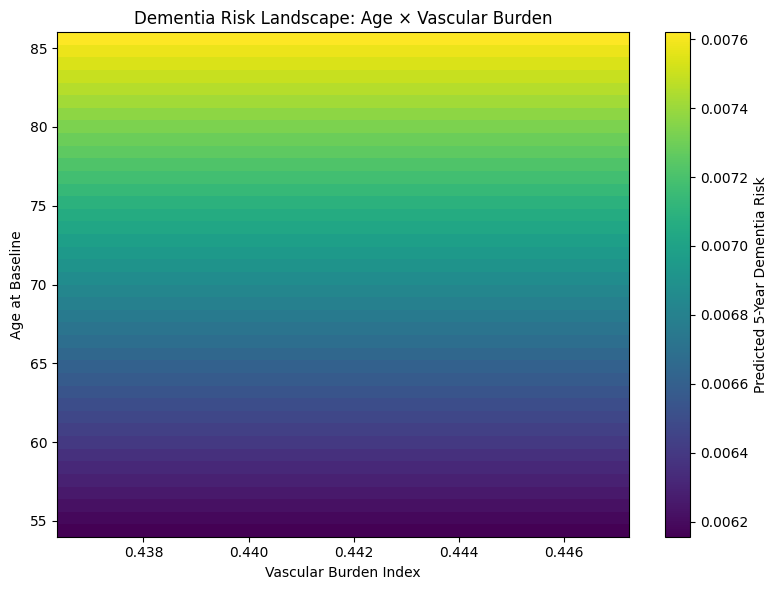

In [ ]:
plt.figure(figsize=(8, 6))
im = plt.imshow(
    risk_matrix,
    aspect="auto",
    origin="lower",
    extent=[vbi_grid.min(), vbi_grid.max(), age_grid.min(), age_grid.max()]
)
plt.colorbar(im, label="Predicted 5-Year Dementia Risk")
plt.xlabel("Vascular Burden Index")
plt.ylabel("Age at Baseline")
plt.title("Dementia Risk Landscape: Age × Vascular Burden")
save_survival_fig("dementia_Risk_Landscape_Age_×_Vascular_Burden.png")
plt.show()

In [ ]:
etiology_risk_table.to_csv(os.path.join(SURVIVAL_OUT_DIR, "etiology_risk_table.csv"), index=False)
risk_group_summary.to_csv(os.path.join(SURVIVAL_OUT_DIR, "risk_group_summary.csv"), index=False)

if "risk_curve_df" in globals():
    risk_curve_df.to_csv(os.path.join(SURVIVAL_OUT_DIR, "etiology_risk_curves_full.csv"), index=False)

print("Saved CSV outputs to:", SURVIVAL_OUT_DIR)

Saved CSV outputs to: ..\output\survival
